# Маркетплейс: продуктовые метрики, экономика привлечения и A/B-тест

# Описание данных

## Таблица `Users`

| Поле              | Описание                                       |
|-------------------|------------------------------------------------|
| `user_id`         | Уникальный идентификатор пользователя.         |
| `registration_date` | Дата регистрации пользователя.                |
| `age`             | Возраст пользователя.                          |
| `gender`          | Пол.                                |
| `region`          | Регион.                                        |
| `acq_channel`     | Канал привлечения.                             |
| `buyer_segment`   | Сегмент покупателя.                            |
| `cohort_week`     | Неделя привлечения.|
| `cohort_month`    | Месяц привлечения. |

---

## Таблица `Events`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `event_id`    | Уникальный идентификатор события.                                        |
| `user_id`     | Идентификатор пользователя.                                              |
| `event_date`  | Дата события.                                                            |
| `event_type`  | Тип события.   |
| `os`          | Операционная система.               |
| `device`      | Тип устройства.                                |
| `product_name`| Наименование товара, к которому относится событие (если применимо).      |
| `event_week`  | Неделя события.                                          |
| `event_month` | Месяц события .                                           |

---

## Таблица `Orders`

| Поле          | Описание                                                                 |
|---------------|--------------------------------------------------------------------------|
| `order_id`    | Уникальный идентификатор заказа.                                         |
| `user_id`     | Идентификатор пользователя, который сделал заказ |
| `order_date`  | Дата и время оформления заказа.                                          |
| `product_name`| Наименование товара.                                                     |
| `quantity`    | Количество единиц товара в заказе.                                       |
| `unit_price`  | Цена за одну единицу товара.                                             |
| `total_price` | Итоговая сумма заказа.                                                   |
| `category_name` | Наименование категории товара.                                         |
| `order_week`  | Неделя заказа.                                           |
| `order_month` | Месяц заказа.                                            |


## Таблица `Campaign_costs`

| Поле         | Описание                                                                 |
|--------------|--------------------------------------------------------------------------|
| `acq_channel`| Канал привлечения.  |
| `spend_month`| Месяц, в который был потрачен бюджет (отражает период, в котором были привлечены пользователи)                      |
| `budget`     | Маркетинговый бюджет (в денежном выражении), потраченный на данный канал в указанном месяце.                           |



## Описание событий

| Событие             | Описание                                                                                  |
|---------------------|-------------------------------------------------------------------------------------------|
| `page_view`         | Открытие любой страницы сайта или приложения пользователем.                                |
| `product_view`      | Просмотр страницы конкретного товара.                                                     |
| `product_click`     | Клик по товару (например, из списка товаров или на баннере).                              |
| `add_to_cart`       | Добавление товара в корзину.                                                              |
| `remove_from_cart`  | Удаление товара из корзины.                                                               |
| `search`            | Выполнение поиска по сайту или приложению.                                                |
| `filter_apply`      | Применение фильтра (например, по цене, бренду, категории).                                |
| `checkout_start`    | Начало оформления заказа (переход к оформлению корзины).                                  |
| `checkout_complete` | Завершение оформления заказа (не гарантирует покупку, покупка зависит от факта оплаты).                                          |
| `user_login`        | Вход пользователя в личный кабинет или аккаунт.                                           |
| `user_logout`       | Выход пользователя из аккаунта.                                                           |
| `wishlist_add`      | Добавление товара в список желаемого (wishlist).                                          |
| `category_view`     | Просмотр страницы категории товаров.                                                      |
| `banner_click`      | Клик по рекламному баннеру на сайте или в приложении.                                     |
| `promo_view`        | Просмотр промо-акции или специального предложения.                                        |


## Выручка маркетплейса = 5% от total_price

# Блок кода и расчета метрик

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
pa_marketplace_orders = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders.csv')
pa_marketplace_campaign_costs = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_campaign_costs.csv')
pa_marketplace_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users.csv')
pa_marketplace_events = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events.csv')

In [3]:
pa_marketplace_orders['order_date'] = pd.to_datetime(pa_marketplace_orders['order_date'])
pa_marketplace_events['event_date'] = pd.to_datetime(pa_marketplace_events['event_date'])
pa_marketplace_users['registration_date'] = pd.to_datetime(pa_marketplace_users['registration_date'])
pa_marketplace_campaign_costs['spend_month'] = pd.to_datetime(pa_marketplace_campaign_costs['spend_month'])

pa_marketplace_orders['month'] = pa_marketplace_orders['order_date'].dt.to_period('M').dt.to_timestamp()
pa_marketplace_events['month'] = pa_marketplace_events['event_date'].dt.to_period('M').dt.to_timestamp()

print('Период заказов:', pa_marketplace_orders['order_date'].min(), '—', pa_marketplace_orders['order_date'].max())
print('Период событий:', pa_marketplace_events['event_date'].min(), '—', pa_marketplace_events['event_date'].max())
print('Дубликаты заказов:', pa_marketplace_orders['order_id'].duplicated().sum())
print('Дубликаты событий:', pa_marketplace_events['event_id'].duplicated().sum())

Период заказов: 2024-01-01 08:03:45 — 2024-12-31 23:00:53
Период событий: 2024-01-01 00:00:00 — 2024-12-31 00:00:00
Дубликаты заказов: 0
Дубликаты событий: 0


### 2. Построить обзор ключевых метрик

На этом этапе вам нужно выполнить верхнеуровневую оценку состояния продукта с помощью собранных витрин. Бизнес просит просто оценить текущее состояние — без глубокой сегментации и оценки сложных метрик.

Выручка бизнеса — 5% комиссии от стоимости любой продажи.

Посмотрите на общую динамику ключевых метрик: например, Revenue, ARPU или ARPPU, MAU, WAU, DAU, AOV, Retention, CTR, CR в заказ. Следовать этому списку необязательно, исходите из данных.

Ваша цель — быстро получить целостную картину, не применяя сегментацию и не рассматривая глубокие срезы. Определите, соответствует ли продукт базовым ожиданиям, виден ли рост, есть ли тревожные сигналы.

Результатом задания будет ваш вывод о динамике основных продуктовых метрик.

#### Подготовка базы месячной активности

Пользователь считается активным, если в месяце у него было событие или заказ. Так все покупатели входят в MAU, даже если событие покупки не попало в журнал событий.

In [4]:
active_events = pa_marketplace_events[['user_id', 'month']].drop_duplicates()
active_orders = pa_marketplace_orders[['user_id', 'month']].drop_duplicates()

monthly_activity = pd.concat([active_events, active_orders])
monthly_activity = monthly_activity.drop_duplicates()
monthly_activity = monthly_activity.sort_values(['user_id', 'month'])


#### Состав MAU и движение аудитории

MAU делится на новых активных, удержанных и вернувшихся пользователей. Ушедшие считаются отдельно для проверки изменения MAU.

In [5]:
monthly_activity['first_month'] = monthly_activity.groupby('user_id')['month'].transform('min')
monthly_activity['previous_month'] = monthly_activity.groupby('user_id')['month'].shift()

one_month = pd.DateOffset(months=1)
monthly_activity['new_active'] = monthly_activity['month'] == monthly_activity['first_month']
monthly_activity['retained'] = monthly_activity['previous_month'] == monthly_activity['month'] - one_month
monthly_activity['returning'] = ~monthly_activity['new_active'] & ~monthly_activity['retained']

In [6]:
mau_components = monthly_activity.groupby('month').agg(
    mau=('user_id', 'nunique'),
    new_active=('new_active', 'sum'),
    retained=('retained', 'sum'),
    returning=('returning', 'sum')
).reset_index()

previous_activity = monthly_activity[['user_id', 'month']].copy()
previous_activity['month'] = previous_activity['month'] + one_month

churn_check = previous_activity.merge(
    monthly_activity[['user_id', 'month']],
    on=['user_id', 'month'],
    how='left',
    indicator=True
)

churned = churn_check[churn_check['_merge'] == 'left_only']
churned = churned.groupby('month')['user_id'].nunique().reset_index(name='churned')
mau_components = mau_components.merge(churned, on='month', how='left')
mau_components['churned'] = mau_components['churned'].fillna(0).astype(int)

#### Месячная витрина метрик

Витрина объединяет аудиторию и заказы. Revenue — комиссия маркетплейса в размере 5% от GMV.

In [7]:
order_metrics = pa_marketplace_orders.groupby('month').agg(
    gmv=('total_price', 'sum'),
    orders=('order_id', 'nunique'),
    buyers=('user_id', 'nunique')
).reset_index()

monthly_metrics = mau_components.merge(order_metrics, on='month', how='left')
monthly_metrics['revenue'] = monthly_metrics['gmv'] * 0.05
monthly_metrics['arpu'] = monthly_metrics['revenue'] / monthly_metrics['mau']
monthly_metrics['cr'] = monthly_metrics['buyers'] / monthly_metrics['mau']
monthly_metrics['arppu'] = monthly_metrics['revenue'] / monthly_metrics['buyers']
monthly_metrics['frequency'] = monthly_metrics['orders'] / monthly_metrics['buyers']
monthly_metrics['aov'] = monthly_metrics['gmv'] / monthly_metrics['orders']
monthly_metrics['retention'] = monthly_metrics['retained'] / monthly_metrics['mau'].shift()
monthly_metrics['mau_change'] = monthly_metrics['mau'].diff()
monthly_metrics['revenue_change'] = monthly_metrics['revenue'].pct_change()

In [8]:
audience_metrics_table = monthly_metrics[[
    'month', 'mau', 'new_active', 'retained',
    'returning', 'churned', 'retention'
]].copy()
audience_metrics_table['retention'] *= 100
audience_metrics_table['month'] = (
    audience_metrics_table['month'].dt.strftime('%Y-%m')
)
audience_metrics_table = audience_metrics_table.rename(columns={
    'month': 'Месяц',
    'mau': 'Активные пользователи (MAU)',
    'new_active': 'Новые',
    'retained': 'Удержанные',
    'returning': 'Вернувшиеся',
    'churned': 'Ушедшие',
    'retention': 'Удержание, %'
})

monetization_metrics_table = monthly_metrics[[
    'month', 'revenue', 'revenue_change', 'arpu',
    'cr', 'arppu', 'frequency', 'aov'
]].copy()
monetization_metrics_table['revenue_change'] *= 100
monetization_metrics_table['cr'] *= 100
monetization_metrics_table['month'] = (
    monetization_metrics_table['month'].dt.strftime('%Y-%m')
)
monetization_metrics_table = monetization_metrics_table.rename(columns={
    'month': 'Месяц',
    'revenue': 'Выручка',
    'revenue_change': 'Изменение выручки, %',
    'arpu': 'Выручка на пользователя (ARPU)',
    'cr': 'Конверсия в покупку, %',
    'arppu': 'Выручка на покупателя (ARPPU)',
    'frequency': 'Заказов на покупателя',
    'aov': 'Средний чек (AOV)'
})

print('Аудиторные метрики по месяцам')
display(audience_metrics_table.round(2))
print('Метрики монетизации по месяцам')
display(monetization_metrics_table.round(2))

Аудиторные метрики по месяцам


,Месяц,Активные пользователи (MAU),Новые,Удержанные,Вернувшиеся,Ушедшие,"Удержание, %"
0,2024-01,1304,1304,0,0,0,NaN
1,2024-02,2392,1674,718,0,586,55.06
2,2024-03,3125,1937,1146,42,1246,47.91
3,2024-04,3341,1909,1380,52,1745,44.16
4,2024-05,3608,1966,1548,94,1793,46.33
5,2024-06,3437,1695,1649,93,1959,45.70
6,2024-07,3809,2233,1487,89,1950,43.26
7,2024-08,4176,2416,1654,106,2155,43.42
8,2024-09,4021,2313,1593,115,2583,38.15
9,2024-10,3824,2120,1564,140,2457,38.90


Метрики монетизации по месяцам


,Месяц,Выручка,"Изменение выручки, %",Выручка на пользователя (ARPU),"Конверсия в покупку, %",Выручка на покупателя (ARPPU),Заказов на покупателя,Средний чек (AOV)
0,2024-01,648890.03,NaN,497.62,34.82,1429.27,2.12,13462.45
1,2024-02,1296557.01,99.81,542.04,35.08,1545.36,2.28,13526.94
2,2024-03,1940749.79,49.68,621.04,37.28,1665.88,2.40,13907.20
3,2024-04,2142838.40,10.41,641.38,39.63,1618.46,2.36,13718.56
4,2024-05,2478758.10,15.68,687.02,38.91,1765.50,2.51,14091.86
5,2024-06,2106011.86,-15.04,612.75,35.79,1712.20,2.49,13773.79
6,2024-07,2446535.45,16.17,642.30,36.36,1766.45,2.46,14336.57
7,2024-08,2465802.40,0.79,590.47,33.17,1780.36,2.45,14534.64
8,2024-09,1935366.70,-21.51,481.31,28.92,1664.12,2.37,14044.75
9,2024-10,1716108.26,-11.33,448.77,26.12,1717.83,2.48,13850.75


#### Настройка визуализаций

In [9]:
plt.style.use('default')
plt.rcParams['font.size'] = 12
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['axes.labelsize'] = 12
plt.rcParams['legend.fontsize'] = 11
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.25
plt.rcParams['axes.axisbelow'] = True

monthly_metrics['month_label'] = monthly_metrics['month'].dt.strftime('%Y-%m')

#### Уровень 1. Выручка

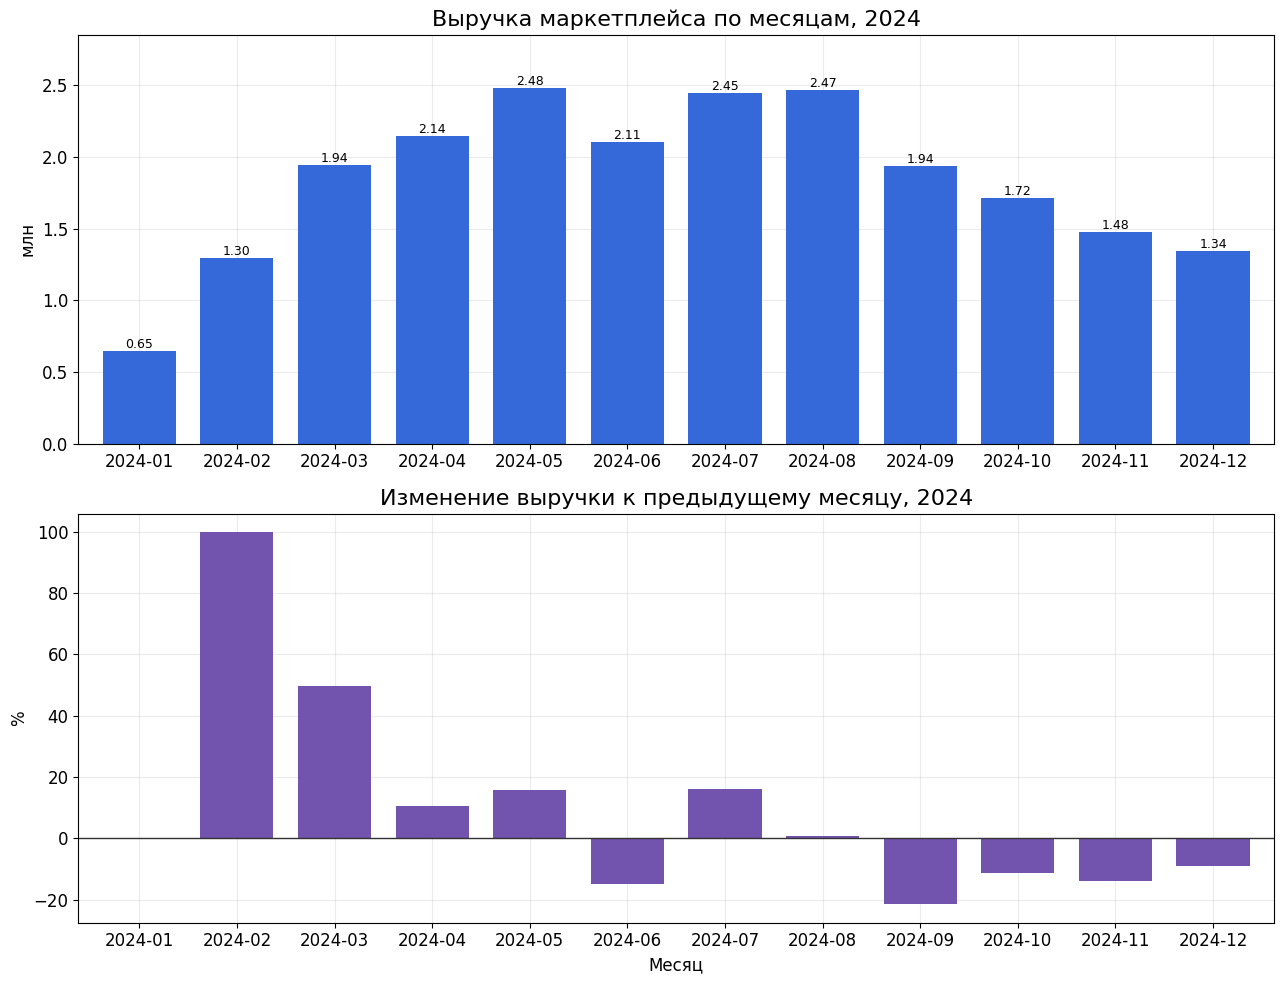

In [10]:
revenue_plot = monthly_metrics.set_index('month_label')

fig, axes = plt.subplots(2, 1, figsize=(13, 10))

revenue_plot['revenue'].div(1_000_000).plot(
    kind='bar', ax=axes[0], color='#3568d8', width=0.75, legend=False
)
for bar in axes[0].patches:
    value = bar.get_height()
    axes[0].text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}',
        ha='center',
        va='bottom',
        fontsize=9
    )
axes[0].margins(y=0.15)
axes[0].set_title('Выручка маркетплейса по месяцам, 2024')
axes[0].set_xlabel('')
axes[0].set_ylabel('млн')
axes[0].tick_params(axis='x', rotation=0)

revenue_plot['revenue_change'].mul(100).plot(
    kind='bar', ax=axes[1], color='#7253ad', width=0.75, legend=False
)
axes[1].axhline(0, color='#333333', linewidth=1)
axes[1].set_title('Изменение выручки к предыдущему месяцу, 2024')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

##### Промежуточный вывод по выручке

Выручка выросла с 0,65 млн в январе до 2,48 млн в мае. После восстановления в июле–августе она снижалась четыре месяца подряд и достигла 1,34 млн в декабре — на 45,6% ниже августа.

#### Уровень 2. Выручка = MAU × ARPU

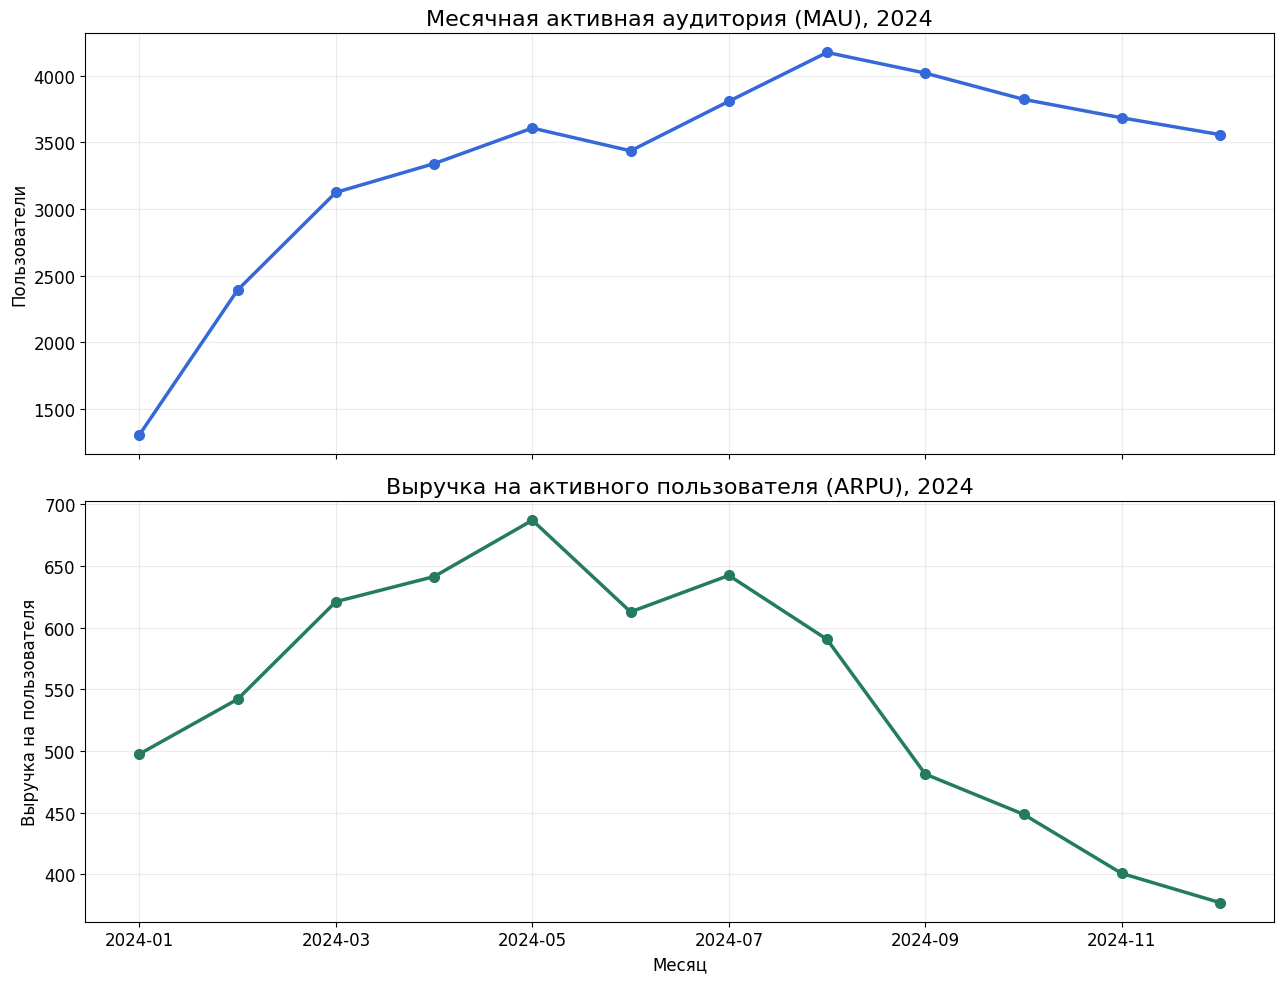

In [11]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)

monthly_metrics.plot(
    x='month_label', y='mau', marker='o', markersize=7, linewidth=2.5,
    ax=axes[0], legend=False, color='#3568d8'
)
axes[0].set_title('Месячная активная аудитория (MAU), 2024')
axes[0].set_xlabel('')
axes[0].set_ylabel('Пользователи')

monthly_metrics.plot(
    x='month_label', y='arpu', marker='o', markersize=7, linewidth=2.5,
    ax=axes[1], legend=False, color='#247b62'
)
axes[1].set_title('Выручка на активного пользователя (ARPU), 2024')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Выручка на пользователя')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

##### Промежуточный вывод по MAU и ARPU

Месячная активная аудитория достигла 4 176 пользователей в августе и снизилась до 3 559 в декабре, или на 14,8%. За тот же период выручка на активного пользователя упала с 590 до 377, или на 36,1%. Поэтому снижение выручки связано прежде всего с ухудшением монетизации активной аудитории.

#### Ветка MAU: новые, удержанные, вернувшиеся и ушедшие

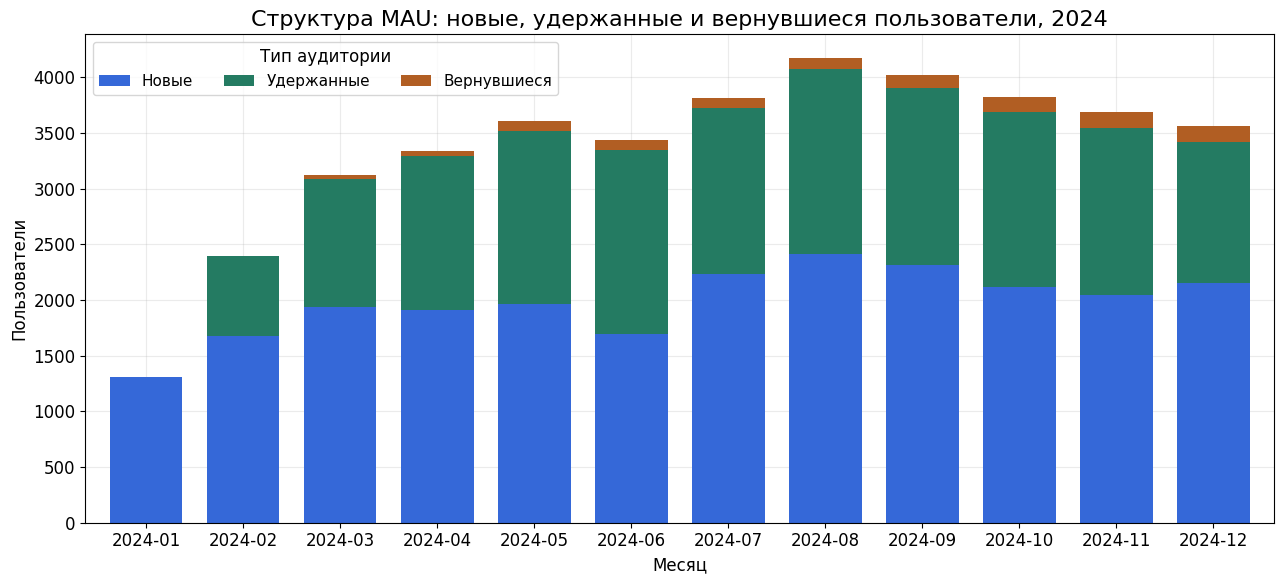

In [12]:
audience_structure = monthly_metrics.set_index('month_label')[['new_active', 'retained', 'returning']]
audience_structure.columns = ['Новые', 'Удержанные', 'Вернувшиеся']

ax = audience_structure.plot(
    kind='bar', stacked=True, figsize=(13, 6),
    color=['#3568d8', '#247b62', '#b15e23'], width=0.75
)
ax.set_title('Структура MAU: новые, удержанные и вернувшиеся пользователи, 2024')
ax.set_xlabel('Месяц')
ax.set_ylabel('Пользователи')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='Тип аудитории', ncol=3, loc='upper left')
plt.tight_layout()
plt.show()

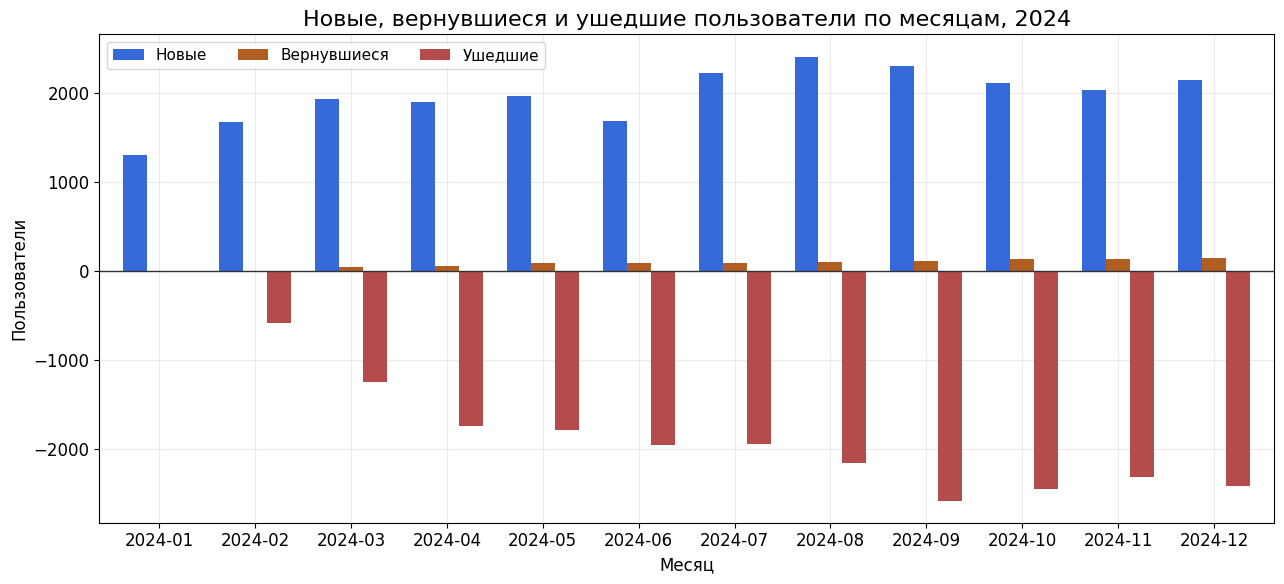

In [13]:
audience_flow = monthly_metrics.set_index('month_label')[['new_active', 'returning', 'churned']].copy()
audience_flow.columns = ['Новые', 'Вернувшиеся', 'Ушедшие']
audience_flow['Ушедшие'] = -audience_flow['Ушедшие']

ax = audience_flow.plot(
    kind='bar', figsize=(13, 6), color=['#3568d8', '#b15e23', '#b44c4c'], width=0.75
)
ax.axhline(0, color='#333333', linewidth=1)
ax.set_title('Новые, вернувшиеся и ушедшие пользователи по месяцам, 2024')
ax.set_xlabel('Месяц')
ax.set_ylabel('Пользователи')
ax.tick_params(axis='x', rotation=0)
ax.legend(ncol=3, loc='upper left')
plt.tight_layout()
plt.show()

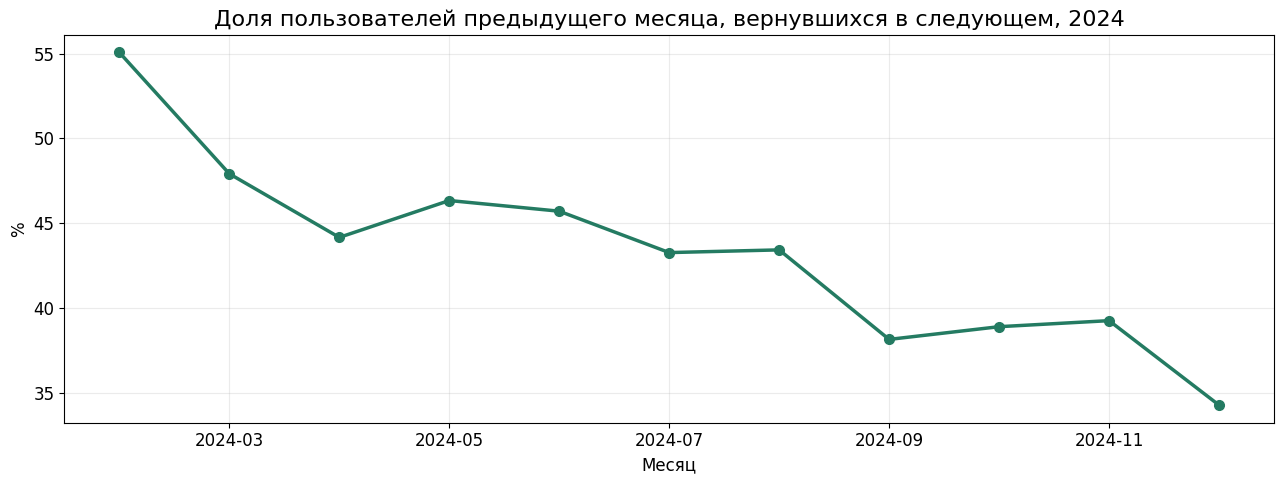

In [14]:
monthly_metrics['retention_percent'] = monthly_metrics['retention'] * 100

ax = monthly_metrics.plot(
    x='month_label', y='retention_percent', figsize=(13, 5), marker='o',
    markersize=7, linewidth=2.5, legend=False, color='#247b62'
)
ax.set_title('Доля пользователей предыдущего месяца, вернувшихся в следующем, 2024')
ax.set_xlabel('Месяц')
ax.set_ylabel('%')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

##### Промежуточный вывод по составу MAU

Удержание следующего месяца снизилось с 55,1% в феврале до 34,3% в декабре. После августа число удержанных пользователей сократилось с 1 654 до 1 263. В сентябре–декабре новые и вернувшиеся пользователи не компенсировали отток, поэтому MAU снижалась.

#### Ветка ARPU: конверсия в покупку × ARPPU

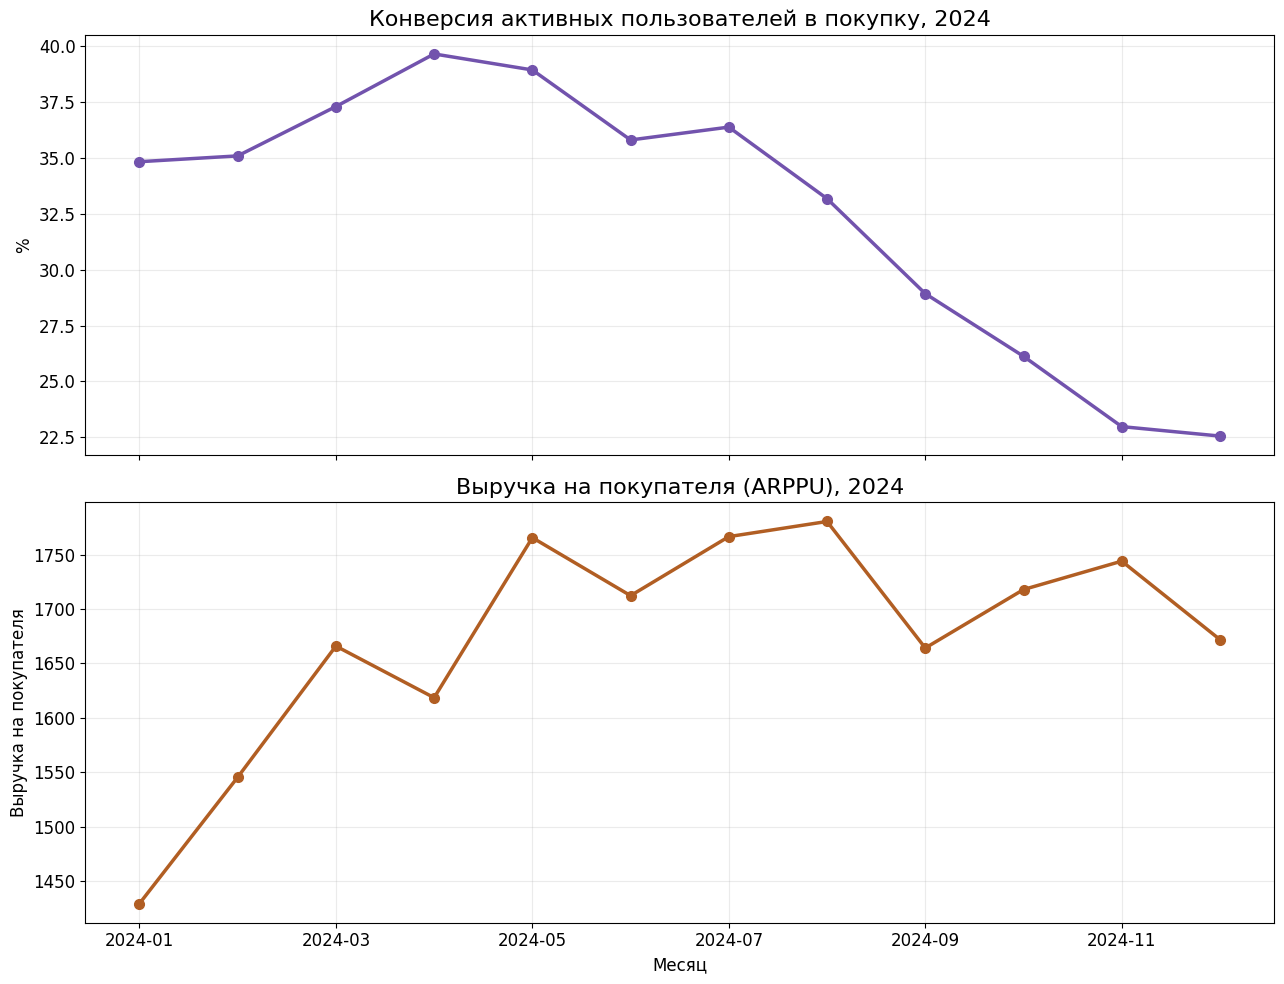

In [15]:
monthly_metrics['cr_percent'] = monthly_metrics['cr'] * 100

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
monthly_metrics.plot(
    x='month_label', y='cr_percent', marker='o', markersize=7, linewidth=2.5,
    ax=axes[0], legend=False, color='#7253ad'
)
axes[0].set_title('Конверсия активных пользователей в покупку, 2024')
axes[0].set_xlabel('')
axes[0].set_ylabel('%')

monthly_metrics.plot(
    x='month_label', y='arppu', marker='o', markersize=7, linewidth=2.5,
    ax=axes[1], legend=False, color='#b15e23'
)
axes[1].set_title('Выручка на покупателя (ARPPU), 2024')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Выручка на покупателя')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

##### Промежуточный вывод по конверсии и ARPPU

Конверсия в покупку достигла 39,6% в апреле, затем снизилась до 33,2% в августе и 22,6% в декабре. Выручка на покупателя оставалась в диапазоне 1,62–1,78 тыс. и с августа по декабрь снизилась только на 6,1%. Следовательно, ARPU падает главным образом из-за уменьшения доли покупателей.

#### Ветка ARPPU: частота покупок × средний чек × 5%

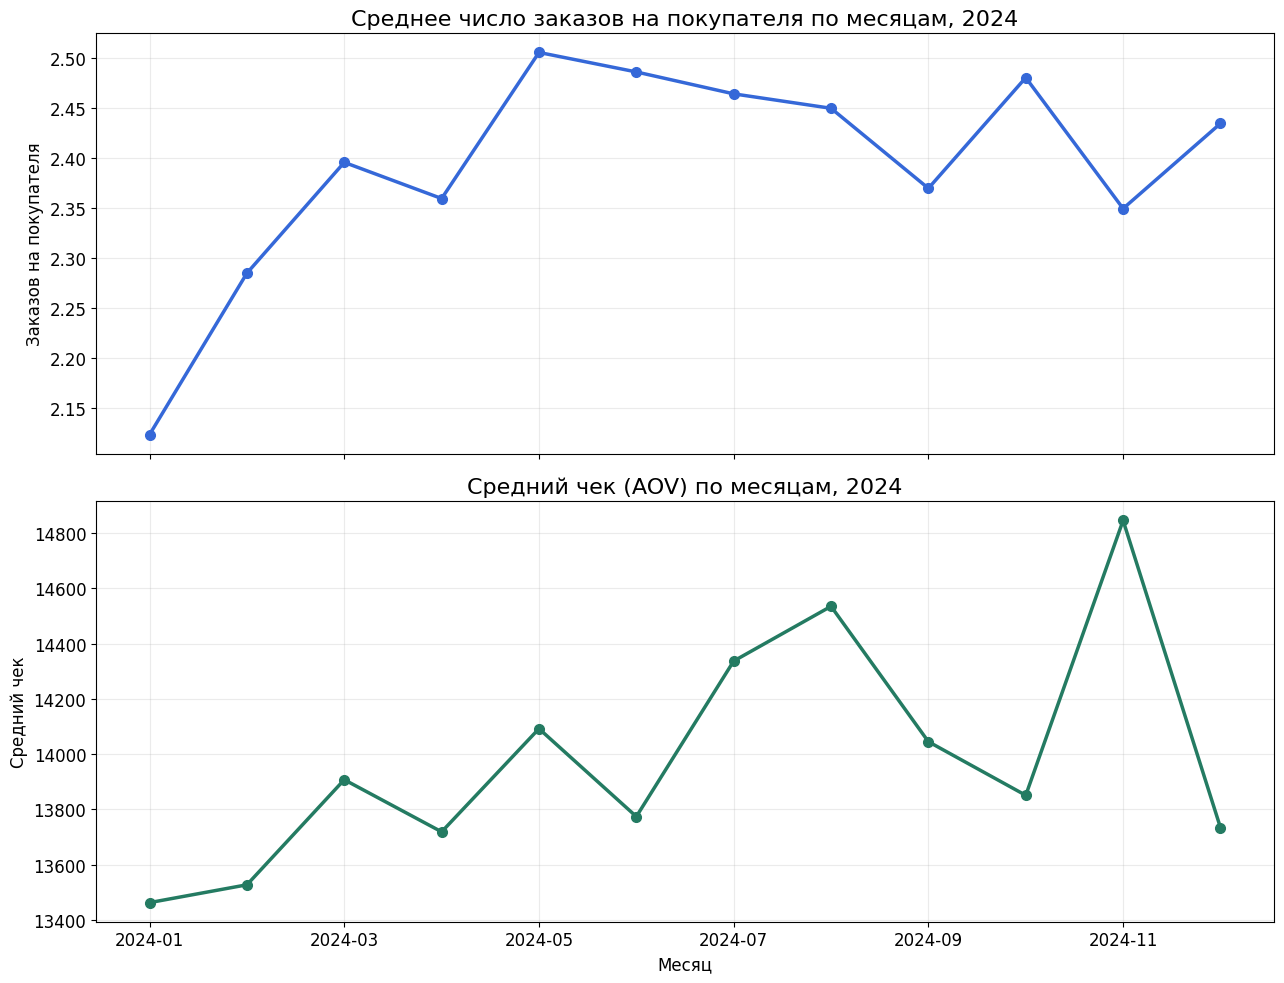

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
monthly_metrics.plot(
    x='month_label', y='frequency', marker='o', markersize=7, linewidth=2.5,
    ax=axes[0], legend=False, color='#3568d8'
)
axes[0].set_title('Среднее число заказов на покупателя по месяцам, 2024')
axes[0].set_xlabel('')
axes[0].set_ylabel('Заказов на покупателя')

monthly_metrics.plot(
    x='month_label', y='aov', marker='o', markersize=7, linewidth=2.5,
    ax=axes[1], legend=False, color='#247b62'
)
axes[1].set_title('Средний чек (AOV) по месяцам, 2024')
axes[1].set_xlabel('Месяц')
axes[1].set_ylabel('Средний чек')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

##### Промежуточный вывод по частоте покупок и среднему чеку

Частота покупок находилась в диапазоне 2,12–2,51 заказа на покупателя, а средний чек — 13,46–14,85 тыс. У этих метрик нет устойчивого нисходящего тренда, поэтому они не объясняют основную часть падения выручки.

#### Проверка формул дерева

In [17]:
monthly_metrics['revenue_check_1'] = monthly_metrics['mau'] * monthly_metrics['arpu']
monthly_metrics['revenue_check_2'] = monthly_metrics['mau'] * monthly_metrics['cr'] * monthly_metrics['arppu']
monthly_metrics['revenue_check_3'] = (
    monthly_metrics['mau']
    * monthly_metrics['cr']
    * monthly_metrics['frequency']
    * monthly_metrics['aov']
    * 0.05
)

mau_parts = monthly_metrics['new_active'] + monthly_metrics['retained'] + monthly_metrics['returning']
mau_flow = monthly_metrics['new_active'] + monthly_metrics['returning'] - monthly_metrics['churned']

formula_errors = pd.DataFrame({
    'Формула': [
        'MAU = новые + удержанные + вернувшиеся',
        'ΔMAU = новые + вернувшиеся − ушедшие',
        'Выручка = MAU × ARPU',
        'Выручка = MAU × конверсия × ARPPU',
        'Выручка = MAU × конверсия × частота × средний чек × 5%'
    ],
    'Максимальное расхождение': [
        (monthly_metrics['mau'] - mau_parts).abs().max(),
        (monthly_metrics['mau_change'].iloc[1:] - mau_flow.iloc[1:]).abs().max(),
        (monthly_metrics['revenue'] - monthly_metrics['revenue_check_1']).abs().max(),
        (monthly_metrics['revenue'] - monthly_metrics['revenue_check_2']).abs().max(),
        (monthly_metrics['revenue'] - monthly_metrics['revenue_check_3']).abs().max()
    ]
})

print('Проверка формул дерева метрик')
display(formula_errors.round(8))

Проверка формул дерева метрик


,Формула,Максимальное расхождение
0,MAU = новые + удержанные + вернувшиеся,0.0
1,ΔMAU = новые + вернувшиеся − ушедшие,0.0
2,Выручка = MAU × ARPU,0.0
3,Выручка = MAU × конверсия × ARPPU,0.0
4,Выручка = MAU × конверсия × частота × средний ...,0.0


### Выводы по обзору ключевых метрик

- С августа по декабрь выручка снизилась на 45,6%.
- MAU за тот же период сократилась на 14,8%, а ARPU — на 36,1%.
- Основной фактор падения ARPU — снижение конверсии в покупку до 22,6%.
- Выручка на покупателя, частота покупок и средний чек менялись значительно слабее.
- Одновременно удержание снизилось до 34,3%, а число удержанных пользователей после августа сократилось на 23,6%.

Дальнейший анализ должен проверить снижение конверсии и удержания по каналам и пользовательским сегментам.

### 3. Оценка метрик монетизации и юнит-экономики

Выполните анализ монетизации. Определите, сколько зарабатывает продукт и сколько тратит на привлечение.

Важны как агрегированные метрики (ARPU, AOV), так и показатели эффективности (CAC, ROI, Payback Period).

Сформулируйте первые выводы по результатам анализа метрик. Сделайте это в формате записки для заказчика. Изложите все основные результаты так, чтобы прослеживалась связь между мыслями. Не пишите много — заказчик не будет читать записку полностью, а просто просмотрит.

Напишите выводы в конце блока, чтобы заказчик мог быстро ознакомиться с основными результатами.

#### 3.1. Маркетинговые расходы и календарный ROMI

In [18]:
marketing_spend = pa_marketplace_campaign_costs.groupby('spend_month')['budget'].sum()
marketing_spend = marketing_spend.reset_index(name='marketing_spend')
marketing_spend = marketing_spend.rename(columns={'spend_month': 'month'})

marketing_monthly = monthly_metrics[['month', 'revenue']].merge(
    marketing_spend, on='month', how='left'
)
marketing_monthly['marketing_result'] = (
    marketing_monthly['revenue'] - marketing_monthly['marketing_spend']
)
marketing_monthly['romi'] = (
    marketing_monthly['marketing_result'] / marketing_monthly['marketing_spend']
)
marketing_monthly['month_label'] = marketing_monthly['month'].dt.strftime('%Y-%m')


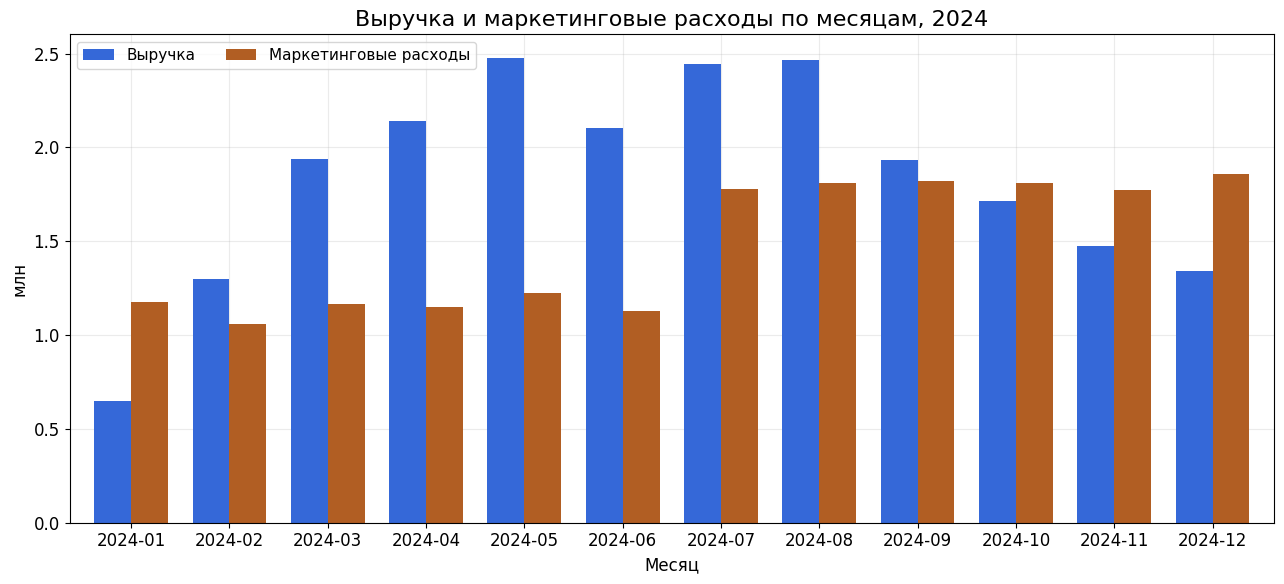

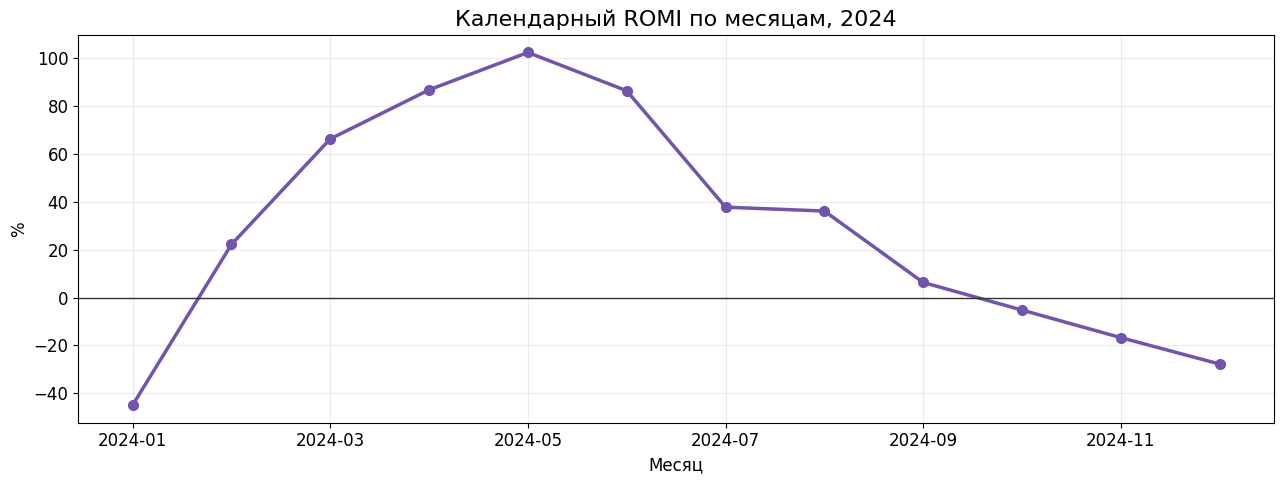

In [19]:
spend_plot = marketing_monthly.set_index('month_label')[['revenue', 'marketing_spend']]
spend_plot = spend_plot.div(1_000_000)
spend_plot.columns = ['Выручка', 'Маркетинговые расходы']

ax = spend_plot.plot(
    kind='bar', figsize=(13, 6), color=['#3568d8', '#b15e23'], width=0.75
)
ax.set_title('Выручка и маркетинговые расходы по месяцам, 2024')
ax.set_xlabel('Месяц')
ax.set_ylabel('млн')
ax.tick_params(axis='x', rotation=0)
ax.legend(ncol=2, loc='upper left')
plt.tight_layout()
plt.show()

marketing_monthly['romi_percent'] = marketing_monthly['romi'] * 100
ax = marketing_monthly.plot(
    x='month_label', y='romi_percent', figsize=(13, 5), marker='o',
    markersize=7, linewidth=2.5, legend=False, color='#7253ad'
)
ax.axhline(0, color='#333333', linewidth=1)
ax.set_title('Календарный ROMI по месяцам, 2024')
ax.set_xlabel('Месяц')
ax.set_ylabel('%')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

##### Промежуточный вывод по расходам и календарному ROMI

Во втором полугодии маркетинговые расходы выросли, но выручка не увеличилась вслед за ними. К концу года календарный ROMI стал отрицательным. Поскольку календарный показатель смешивает разные когорты, основная оценка эффективности далее проводится когортно.

#### 3.2. Стоимость привлечения пользователя (CAC)

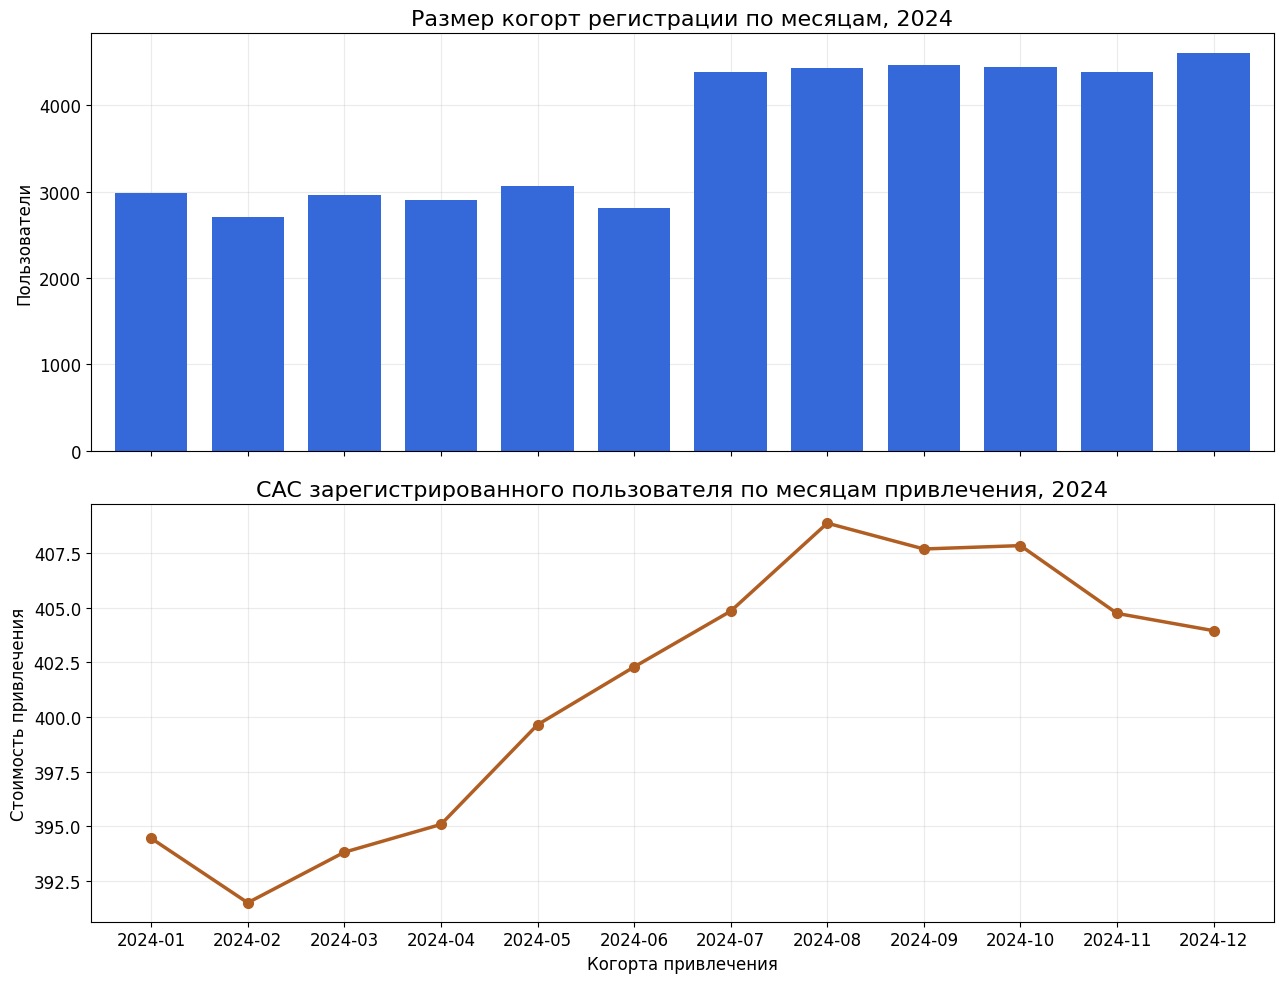

Размер когорт и стоимость привлечения


,Когорта,Новые пользователи,Маркетинговые расходы,Стоимость привлечения (CAC)
0,2024-01,2985,1177456.97,394.46
1,2024-02,2711,1061385.93,391.51
2,2024-03,2965,1167680.37,393.82
3,2024-04,2905,1147739.92,395.09
4,2024-05,3066,1225322.28,399.65
5,2024-06,2810,1130439.77,402.29
6,2024-07,4388,1776446.60,404.84
7,2024-08,4431,1811677.75,408.86
8,2024-09,4466,1820718.83,407.68
9,2024-10,4440,1810802.57,407.84


In [20]:
cohort_sizes = pa_marketplace_users.groupby('cohort_month')['user_id'].nunique()
cohort_sizes = cohort_sizes.reset_index(name='new_users')
cohort_sizes['cohort_month'] = pd.to_datetime(cohort_sizes['cohort_month'])

acquisition_metrics = cohort_sizes.merge(
    marketing_spend, left_on='cohort_month', right_on='month', how='left'
)
acquisition_metrics['cac'] = (
    acquisition_metrics['marketing_spend'] / acquisition_metrics['new_users']
)
acquisition_metrics['cohort_label'] = acquisition_metrics['cohort_month'].dt.strftime('%Y-%m')

fig, axes = plt.subplots(2, 1, figsize=(13, 10), sharex=True)
acquisition_metrics.plot(
    x='cohort_label', y='new_users', kind='bar', ax=axes[0],
    color='#3568d8', width=0.75, legend=False
)
axes[0].set_title('Размер когорт регистрации по месяцам, 2024')
axes[0].set_xlabel('')
axes[0].set_ylabel('Пользователи')

acquisition_metrics.plot(
    x='cohort_label', y='cac', marker='o', markersize=7, linewidth=2.5,
    ax=axes[1], color='#b15e23', legend=False
)
axes[1].set_title('CAC зарегистрированного пользователя по месяцам привлечения, 2024')
axes[1].set_xlabel('Когорта привлечения')
axes[1].set_ylabel('Стоимость привлечения')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

acquisition_table = acquisition_metrics[[
    'cohort_month', 'new_users', 'marketing_spend', 'cac'
]].copy()
acquisition_table['cohort_month'] = (
    acquisition_table['cohort_month'].dt.strftime('%Y-%m')
)
acquisition_table = acquisition_table.rename(columns={
    'cohort_month': 'Когорта',
    'new_users': 'Новые пользователи',
    'marketing_spend': 'Маркетинговые расходы',
    'cac': 'Стоимость привлечения (CAC)'
})

print('Размер когорт и стоимость привлечения')
display(acquisition_table.round(2))

##### Промежуточный вывод по CAC

После увеличения бюджета число зарегистрированных пользователей выросло примерно с 2,7–3,1 тыс. в первом полугодии до 4,4–4,6 тыс. во втором. При этом CAC пользователя оставался стабильным в диапазоне 392–409. Маркетинг продолжал привлекать регистрации по прежней цене, однако CAC регистрации сам по себе не отражает качество аудитории и её способность приносить выручку.

#### 3.3. Когортная ценность клиента (LTV)

In [21]:
user_cohorts = pa_marketplace_users[['user_id', 'cohort_month']].copy()
user_cohorts['cohort_month'] = pd.to_datetime(user_cohorts['cohort_month'])

cohort_orders = pa_marketplace_orders.merge(user_cohorts, on='user_id', how='left')
cohort_orders['lifetime_month'] = (
    (cohort_orders['month'].dt.year - cohort_orders['cohort_month'].dt.year) * 12
    + cohort_orders['month'].dt.month
    - cohort_orders['cohort_month'].dt.month
)
cohort_orders['revenue'] = cohort_orders['total_price'] * 0.05

cohort_revenue = cohort_orders.pivot_table(
    index='cohort_month', columns='lifetime_month',
    values='revenue', aggfunc='sum', fill_value=0
)
cumulative_revenue = cohort_revenue.cumsum(axis=1)
cohort_size_series = cohort_sizes.set_index('cohort_month')['new_users']
ltv = cumulative_revenue.div(cohort_size_series, axis=0)

last_order_month = pa_marketplace_orders['month'].max()
for cohort_month in ltv.index:
    max_lifetime = (
        (last_order_month.year - cohort_month.year) * 12
        + last_order_month.month
        - cohort_month.month
    )
    ltv.loc[cohort_month, ltv.columns > max_lifetime] = float('nan')


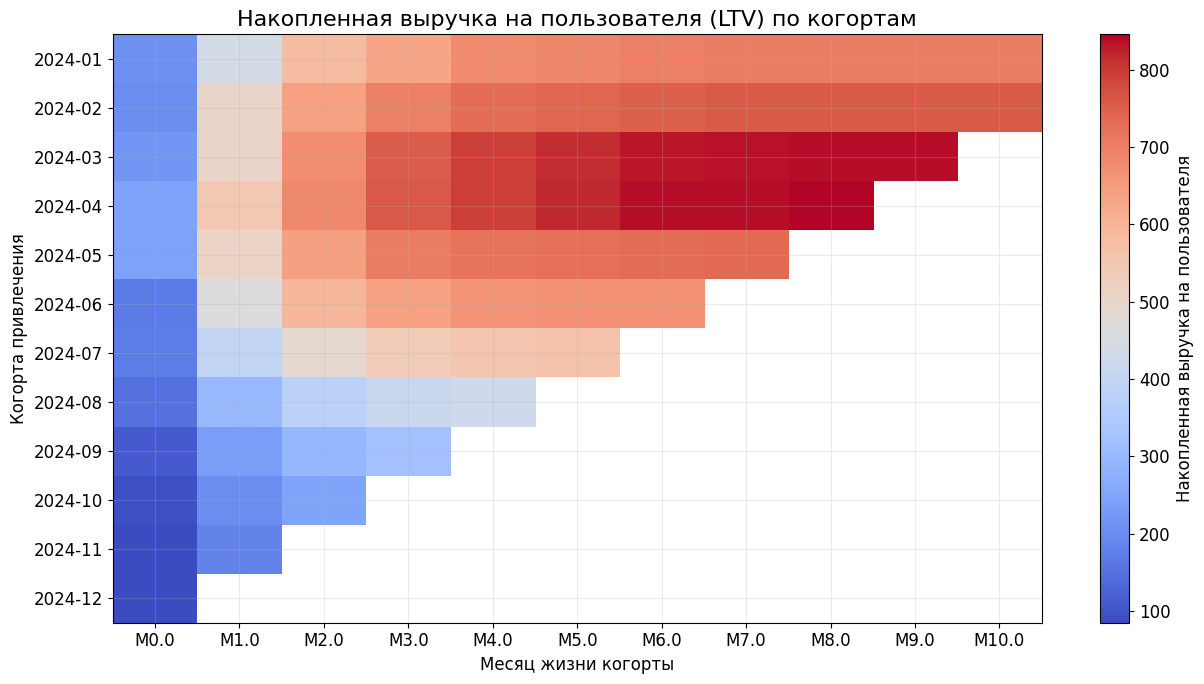

In [22]:
fig, ax = plt.subplots(figsize=(13, 7))
image = ax.imshow(ltv, aspect='auto', cmap='coolwarm')
ax.set_title('Накопленная выручка на пользователя (LTV) по когортам')
ax.set_xlabel('Месяц жизни когорты')
ax.set_ylabel('Когорта привлечения')
ax.set_xticks(range(len(ltv.columns)))
ax.set_xticklabels([f'M{month}' for month in ltv.columns])
ax.set_yticks(range(len(ltv.index)))
ax.set_yticklabels(ltv.index.strftime('%Y-%m'))
fig.colorbar(image, ax=ax, label='Накопленная выручка на пользователя')
plt.tight_layout()
plt.show()

##### Промежуточный вывод по LTV

На одинаковых горизонтах ценность новых когорт последовательно ухудшается. LTV в месяц регистрации снизился с 248 у апрельской когорты до 171 в июле, 151 в августе, 112 в сентябре и примерно 85 в ноябре–декабре. Поздние когорты приносят меньше выручки уже в первые месяцы жизни.

#### 3.4. LTV/CAC и когортный ROMI

In [23]:
cac_by_cohort = acquisition_metrics.set_index('cohort_month')['cac']
ltv_cac = ltv.div(cac_by_cohort, axis=0)

cohort_spend = marketing_spend.set_index('month')['marketing_spend']
cohort_spend = cohort_spend.reindex(cumulative_revenue.index)
cohort_romi = cumulative_revenue.div(cohort_spend, axis=0) - 1

for cohort_month in cohort_romi.index:
    max_lifetime = (
        (last_order_month.year - cohort_month.year) * 12
        + last_order_month.month - cohort_month.month
    )
    cohort_romi.loc[cohort_month, cohort_romi.columns > max_lifetime] = float('nan')


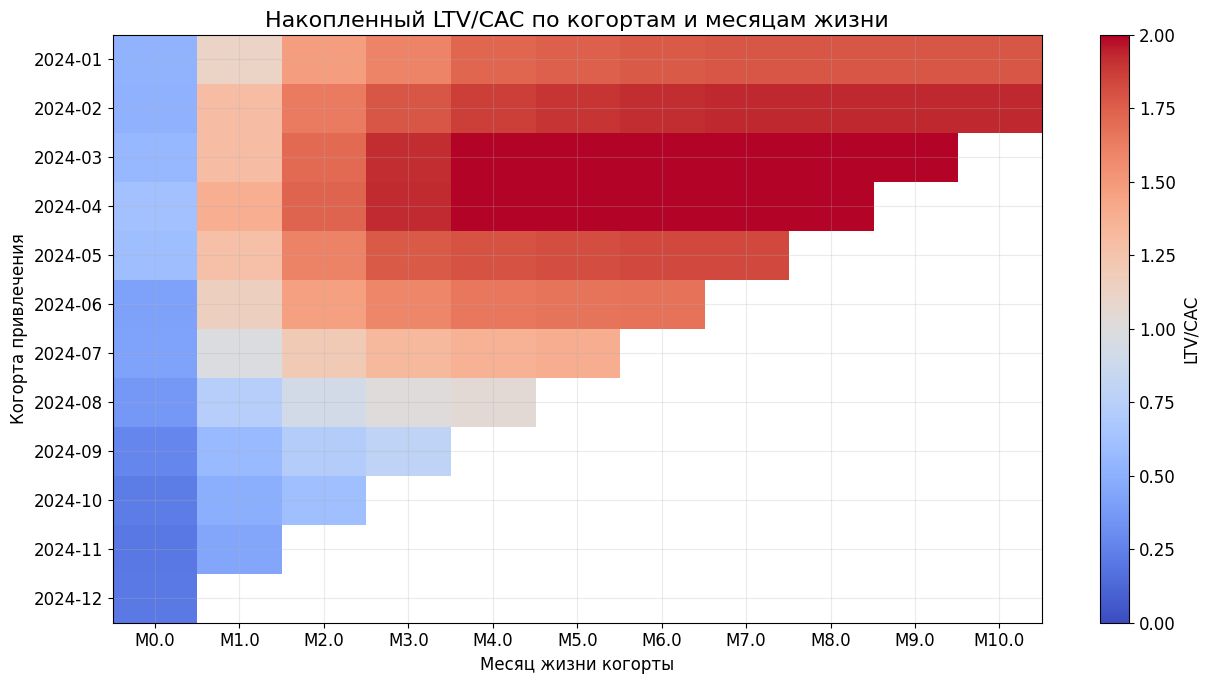

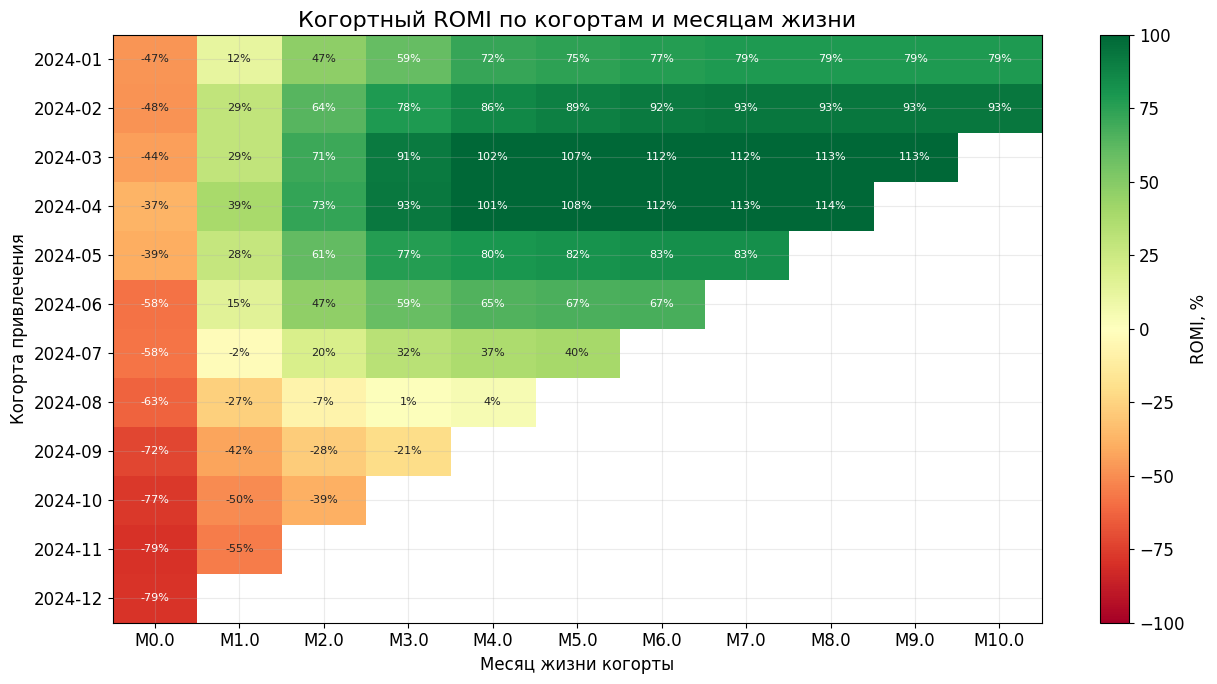

In [24]:
fig, ax = plt.subplots(figsize=(13, 7))
image = ax.imshow(ltv_cac, aspect='auto', cmap='coolwarm', vmin=0, vmax=2)
ax.set_title('Накопленный LTV/CAC по когортам и месяцам жизни')
ax.set_xlabel('Месяц жизни когорты')
ax.set_ylabel('Когорта привлечения')
ax.set_xticks(range(len(ltv_cac.columns)))
ax.set_xticklabels([f'M{month}' for month in ltv_cac.columns])
ax.set_yticks(range(len(ltv_cac.index)))
ax.set_yticklabels(ltv_cac.index.strftime('%Y-%m'))
fig.colorbar(image, ax=ax, label='LTV/CAC')
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(13, 7))
image = ax.imshow(cohort_romi * 100, aspect='auto', cmap='RdYlGn', vmin=-100, vmax=100)
ax.set_title('Когортный ROMI по когортам и месяцам жизни')
ax.set_xlabel('Месяц жизни когорты')
ax.set_ylabel('Когорта привлечения')
ax.set_xticks(range(len(cohort_romi.columns)))
ax.set_xticklabels([f'M{month}' for month in cohort_romi.columns])
ax.set_yticks(range(len(cohort_romi.index)))
ax.set_yticklabels(cohort_romi.index.strftime('%Y-%m'))
for row in range(len(cohort_romi.index)):
    for column in range(len(cohort_romi.columns)):
        value = cohort_romi.iloc[row, column]
        if pd.notna(value):
            color = 'white' if abs(value) > 0.55 else '#222222'
            ax.text(column, row, f'{value:.0%}', ha='center', va='center', color=color, fontsize=8)
fig.colorbar(image, ax=ax, label='ROMI, %')
plt.tight_layout()
plt.show()

#### 3.5. Срок окупаемости

In [25]:
payback_rows = []

for cohort_month in ltv_cac.index:
    available_ratio = ltv_cac.loc[cohort_month].dropna()
    reached_payback = available_ratio[available_ratio >= 1]

    payback_month = pd.NA
    if not reached_payback.empty:
        payback_month = reached_payback.index.min()

    payback_rows.append({
        'cohort_month': cohort_month,
        'cac': cac_by_cohort.loc[cohort_month],
        'ltv_m0': ltv.loc[cohort_month, 0],
        'ltv_m1': ltv.loc[cohort_month, 1],
        'ltv_m2': ltv.loc[cohort_month, 2],
        'payback_month': payback_month,
    })

payback_table = pd.DataFrame(payback_rows)
payback_table['status'] = 'Не окупилась за доступный период'
payback_table.loc[payback_table['payback_month'].notna(), 'status'] = 'Окупилась'
payback_table['cohort_label'] = payback_table['cohort_month'].dt.strftime('%Y-%m')

payback_display = payback_table[[
    'cohort_month', 'cac', 'ltv_m0', 'ltv_m1', 'ltv_m2',
    'payback_month', 'status'
]].copy()
payback_display['cohort_month'] = (
    payback_display['cohort_month'].dt.strftime('%Y-%m')
)
payback_display['payback_month'] = payback_display[
    'payback_month'
].map(
    lambda value: '—' if pd.isna(value) else f'M{int(value)}'
)
payback_display = payback_display.rename(columns={
    'cohort_month': 'Когорта',
    'cac': 'CAC',
    'ltv_m0': 'LTV M0',
    'ltv_m1': 'LTV M1',
    'ltv_m2': 'LTV M2',
    'payback_month': 'Месяц окупаемости',
    'status': 'Статус'
})

print('Срок окупаемости когорт')
display(payback_display.round(2))

Срок окупаемости когорт


,Когорта,CAC,LTV M0,LTV M1,LTV M2,Месяц окупаемости,Статус
0,2024-01,394.46,208.87,441.05,579.47,M1,Окупилась
1,2024-02,391.51,203.16,505.33,640.59,M1,Окупилась
2,2024-03,393.82,219.61,508.87,673.61,M1,Окупилась
3,2024-04,395.09,248.18,548.36,685.19,M1,Окупилась
4,2024-05,399.65,242.94,511.98,641.66,M1,Окупилась
5,2024-06,402.29,168.44,463.06,590.82,M1,Окупилась
6,2024-07,404.84,171.11,395.94,486.48,M2,Окупилась
7,2024-08,408.86,151.11,300.32,378.35,M3,Окупилась
8,2024-09,407.68,112.36,235.14,295.55,—,Не окупилась за доступный период
9,2024-10,407.84,93.13,202.14,249.41,—,Не окупилась за доступный период


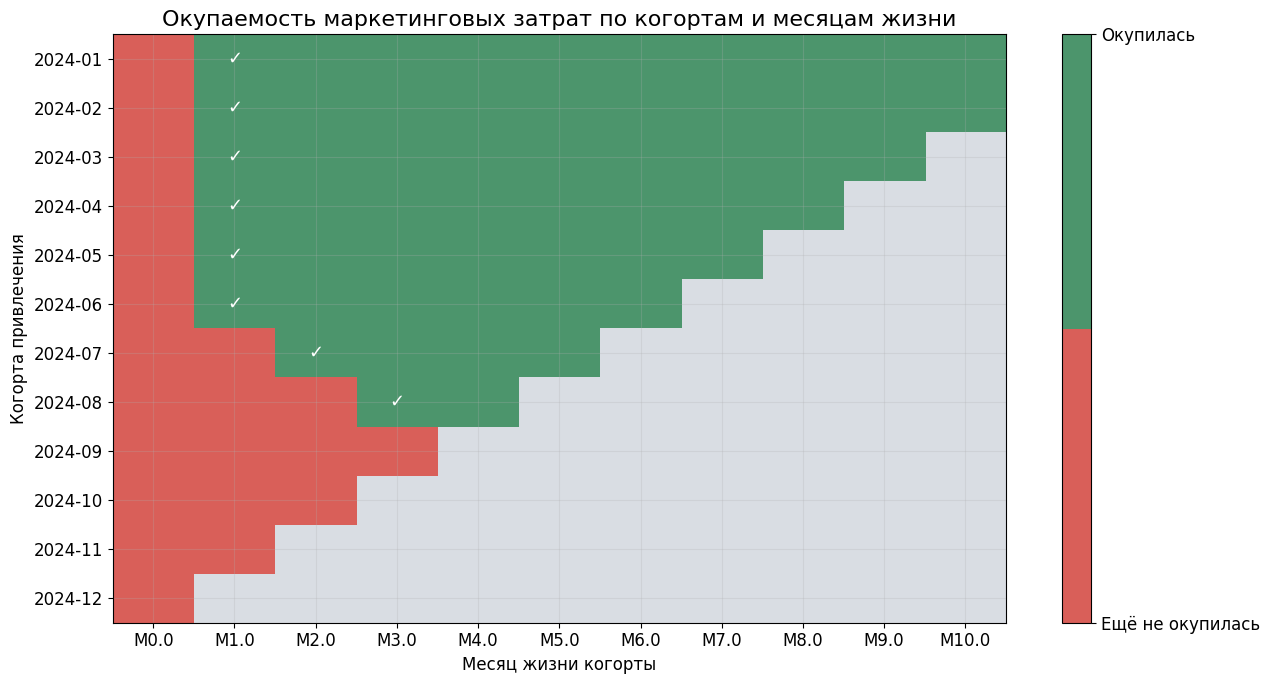

In [26]:
from matplotlib.colors import ListedColormap

payback_matrix = (ltv_cac >= 1).astype(float)
payback_matrix[ltv_cac.isna()] = float('nan')

payback_cmap = ListedColormap(['#d95f59', '#4c956c'])
payback_cmap.set_bad('#d9dde3')

fig, ax = plt.subplots(figsize=(13, 7))
image = ax.imshow(payback_matrix, aspect='auto', cmap=payback_cmap, vmin=0, vmax=1)
ax.set_title('Окупаемость маркетинговых затрат по когортам и месяцам жизни')
ax.set_xlabel('Месяц жизни когорты')
ax.set_ylabel('Когорта привлечения')
ax.set_xticks(range(len(payback_matrix.columns)))
ax.set_xticklabels([f'M{month}' for month in payback_matrix.columns])
ax.set_yticks(range(len(payback_matrix.index)))
ax.set_yticklabels(payback_matrix.index.strftime('%Y-%m'))

for row_position, cohort_month in enumerate(ltv_cac.index):
    reached_payback = ltv_cac.loc[cohort_month].dropna()
    reached_payback = reached_payback[reached_payback >= 1]
    if not reached_payback.empty:
        first_month = reached_payback.index.min()
        column_position = list(ltv_cac.columns).index(first_month)
        ax.text(column_position, row_position, '✓', ha='center', va='center',
                color='white', fontsize=13, fontweight='bold')

colorbar = fig.colorbar(image, ax=ax, ticks=[0, 1])
colorbar.ax.set_yticklabels(['Ещё не окупилась', 'Окупилась'])
plt.tight_layout()
plt.show()

##### Промежуточный вывод по LTV/CAC, ROMI и сроку окупаемости

На горизонте M2 когортный ROMI снизился с 73,4% у апрельской когорты до 20,2% у июльской, −7,5% у августовской, −27,5% у сентябрьской и −38,8% у октябрьской.

Когорты января–июня окупились на M1, июльская — на M2, августовская — на M3. Сентябрьская и более поздние когорты не окупились на доступном горизонте. Пустые периоды молодых когорт не считаются отсутствием окупаемости.

Календарный ROMI сохранён как справочный показатель, а основной анализ эффективности привлечения перестроен на когорты регистрации. Добавлены таблица и тепловая карта когортного ROMI с одинаковым возрастом когорт; выводы по окупаемости уточнены с учётом неполного горизонта молодых когорт.

## Выводы по этапам 2 и 3


После августа состояние продукта ухудшается сразу по двум направлениям: сокращается удержанная аудитория и снижается вероятность покупки. Выручка к декабрю упала заметно сильнее MAU. Основной вклад внесло падение ARPU, связанное со снижением конверсии в покупку. ARPPU, частота заказов и средний чек менялись значительно слабее.

Рост маркетинговых расходов увеличил число регистраций, но не улучшил экономику привлечения. При близком CAC когортный LTV M2 снизился с 685,2 у апрельской когорты до 249,4 у октябрьской. Одновременно ROMI M2 изменился с 73,4% до −38,8%, а срок окупаемости удлинился. Ухудшение видно уже на одинаковом горизонте M0–M2, поэтому его нельзя объяснить только короткой историей молодых когорт.

Совокупность показателей указывает на две возможные проблемы: изменение качества и структуры привлекаемого трафика, а также снижение повторной активности существующей аудитории. В блоке 4 эти механизмы проверяются помесячно по каналам и сегментам.

## 4. Поиск инсайтов, точек роста и сегментация


### Детализация по сегментам

Анализ каналов привлечения, пользовательских сегментов, категорий товаров, регионов и типов устройств. Цель — выявить потери в воронке, сравнить сегменты и обосновать гипотезы для развития продукта.

### 4.1. Выручка на активного пользователя (ARPU)

ARPU — выручка маркетплейса на одного активного пользователя в месяц.

Метрику рассматриваем помесячно по каналу привлечения, покупательскому сегменту и типу аудитории.

In [27]:
analysis_users = pa_marketplace_users.copy()
analysis_users['cohort_month'] = pd.to_datetime(analysis_users['cohort_month'])

metric_activity = monthly_activity.merge(
    analysis_users[['user_id', 'acq_channel', 'buyer_segment']],
    on='user_id', how='left'
)
metric_activity['audience_type'] = 'Вернувшиеся'
metric_activity.loc[metric_activity['new_active'], 'audience_type'] = 'Новые'
metric_activity.loc[metric_activity['retained'], 'audience_type'] = 'Удержанные'

orders_by_user_month = pa_marketplace_orders.groupby(['user_id', 'month']).agg(
    gmv=('total_price', 'sum'), orders=('order_id', 'nunique')
).reset_index()
orders_by_user_month['revenue'] = orders_by_user_month['gmv'] * 0.05
metric_activity = metric_activity.merge(orders_by_user_month, on=['user_id', 'month'], how='left')
metric_activity[['gmv', 'orders', 'revenue']] = metric_activity[['gmv', 'orders', 'revenue']].fillna(0)
metric_activity['buyer'] = metric_activity['orders'] > 0

dimension_titles = {
    'acq_channel': 'каналам привлечения', 'buyer_segment': 'покупательским сегментам',
    'audience_type': 'типам аудитории', 'device': 'устройствам', 'category_name': 'категориям'
}

arpu_parts = []
arpu_dimensions = ['acq_channel', 'buyer_segment', 'audience_type']
for dimension in arpu_dimensions:
    part = metric_activity.groupby(['month', dimension]).agg(
        active_users=('user_id', 'nunique'), revenue=('revenue', 'sum')
    ).reset_index()
    part['arpu'] = part['revenue'] / part['active_users']
    part = part.rename(columns={dimension: 'segment'})
    part['dimension'] = dimension
    arpu_parts.append(part)

arpu_by_segment = pd.concat(arpu_parts, ignore_index=True)

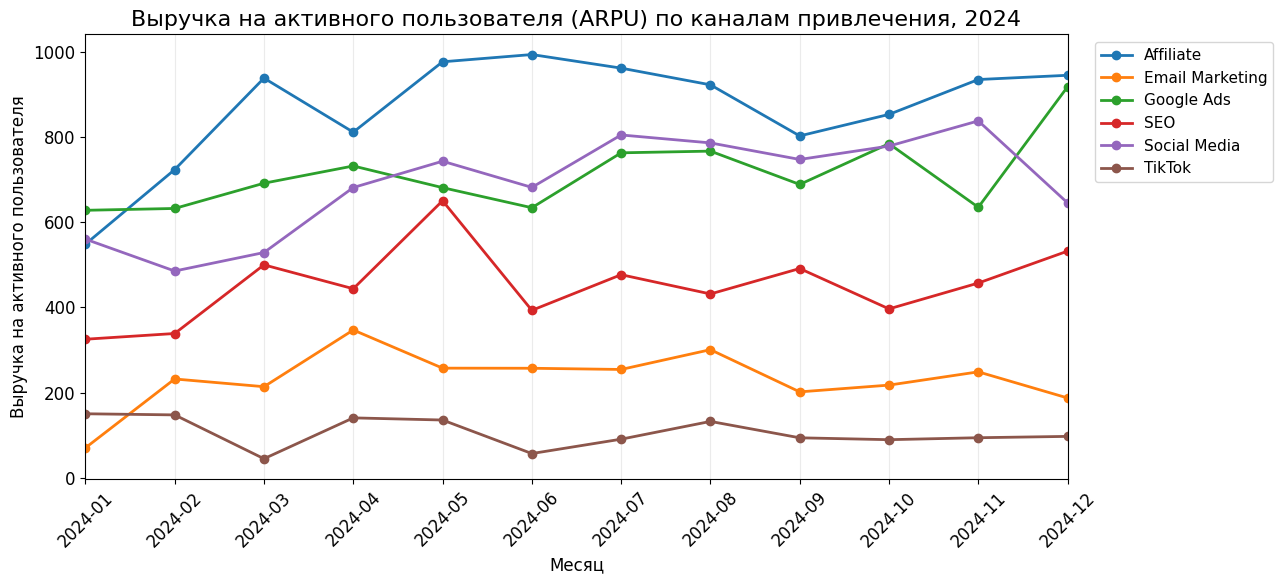

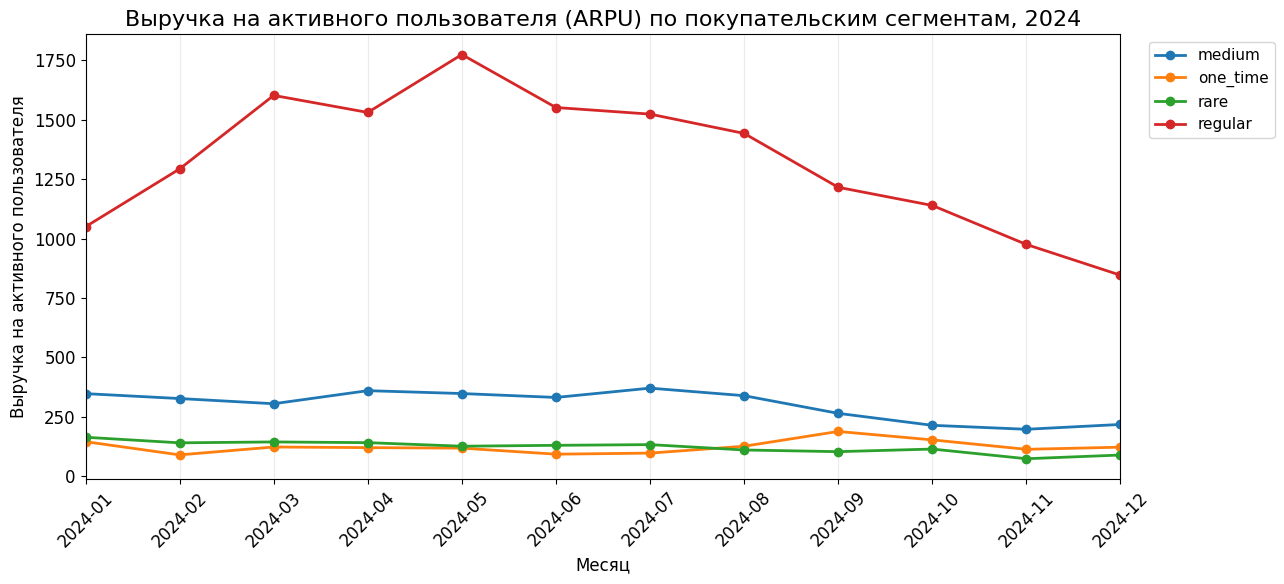

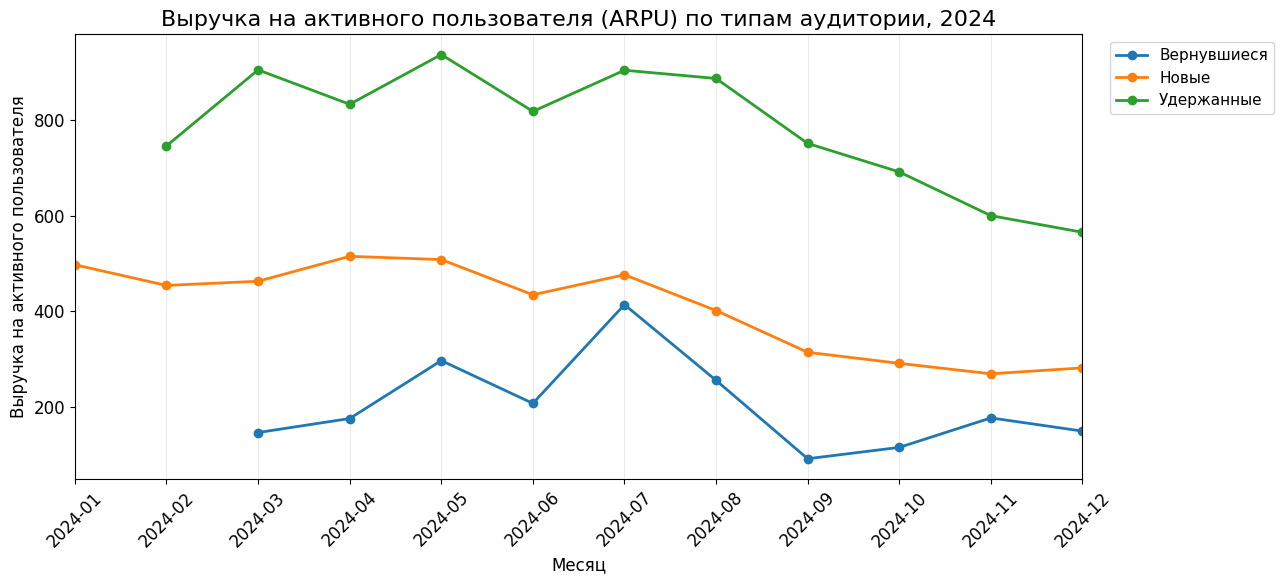

In [28]:
def plot_monthly(data, dimension, value, title, ylabel, top_segments=None):
    plot_data = data[data['dimension'] == dimension].copy()
    if top_segments is not None:
        plot_data = plot_data[plot_data['segment'].isin(top_segments)]
    plot_data = plot_data.pivot(index='month', columns='segment', values=value).sort_index()
    ax = plot_data.plot(figsize=(13, 6), marker='o', linewidth=2)
    ax.set_title(title)
    ax.set_xlabel('Месяц')
    ax.set_ylabel(ylabel)
    ax.set_xticks(plot_data.index)
    ax.set_xticklabels(plot_data.index.strftime('%Y-%m'), rotation=45)
    ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left')
    ax.grid(axis='y', alpha=0.25)
    plt.tight_layout()
    plt.show()

for dimension in arpu_dimensions:
    plot_monthly(
        arpu_by_segment, dimension, 'arpu',
        f"Выручка на активного пользователя (ARPU) по {dimension_titles[dimension]}, 2024",
        'Выручка на активного пользователя'
    )

#### Промежуточный вывод по ARPU

TikTok весь год остаётся каналом с минимальной выручкой на активного пользователя: 45–150 против сотен у большинства других каналов. Одновременно число регистраций TikTok выросло с 394 в январе до 3 506 в декабре.

ARPU также снизился внутри крупных сегментов: у medium — с 347,3 до 217,6, у regular — с 1 049,9 до 845,9, у rare — со 163,7 до 88,8. Значит, общий спад связан и со структурой трафика, и с ухудшением монетизации части аудитории.


### 4.2. Конверсия в покупку

Конверсия — доля активных пользователей месяца, совершивших хотя бы одну покупку.

Метрику рассматриваем помесячно по каналам, покупательским сегментам и типам аудитории. Затем анализируем воронку за последний полный месяц.

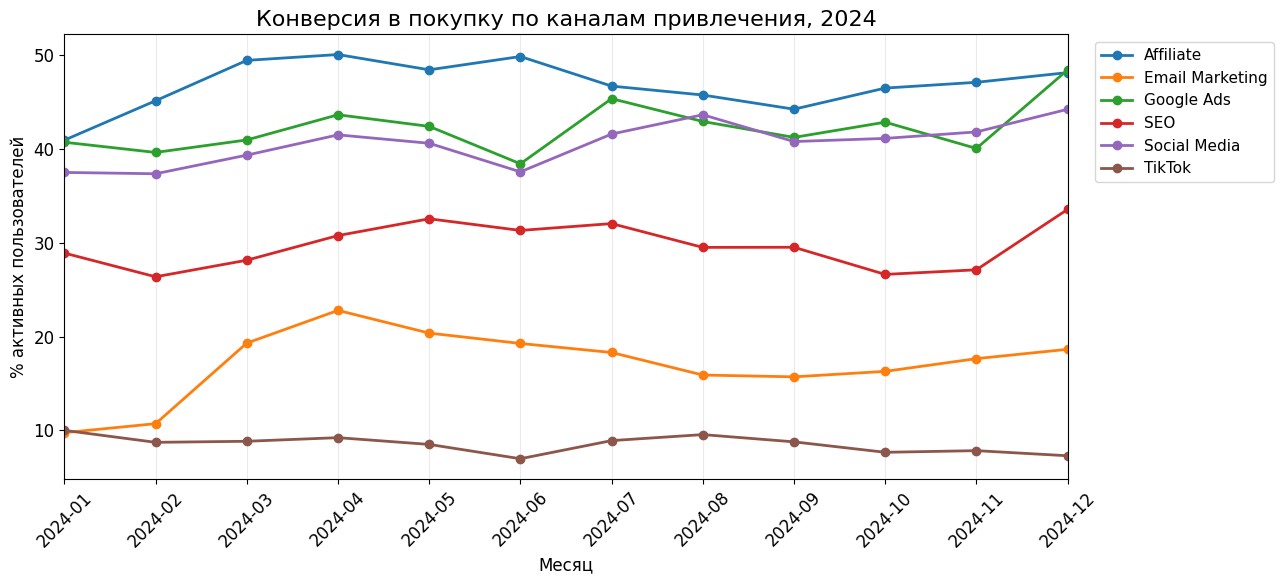

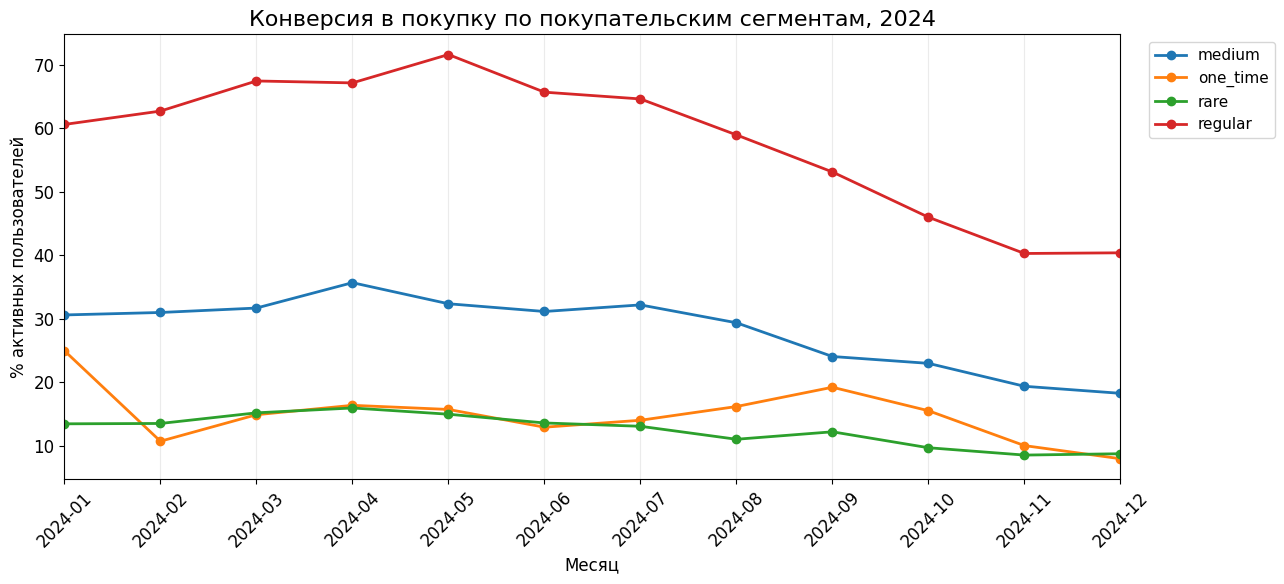

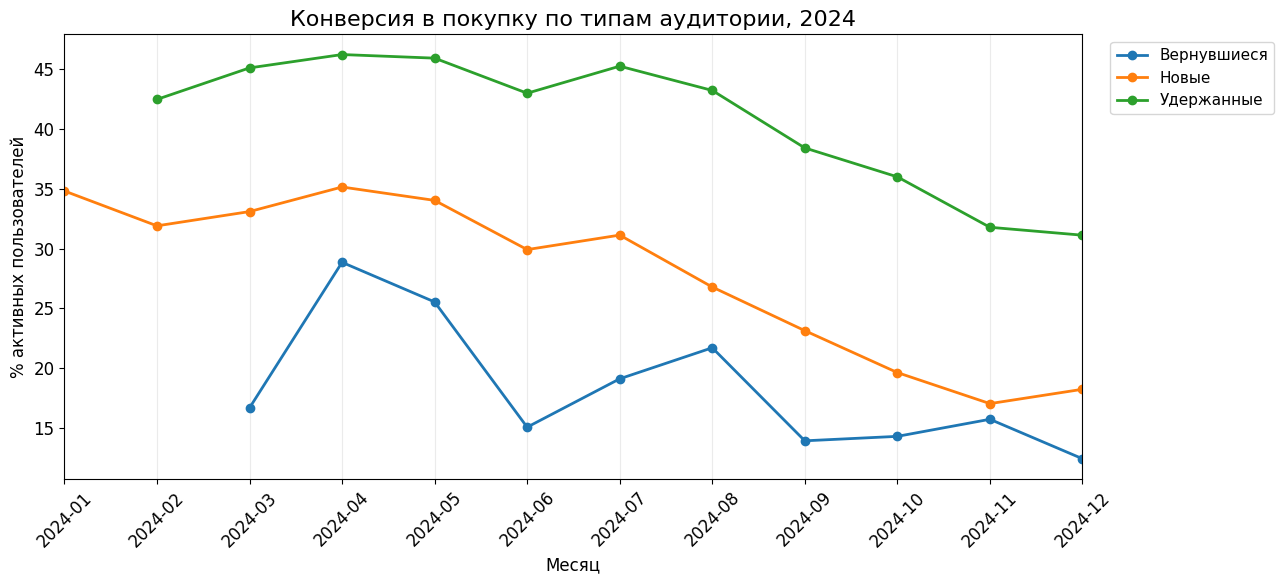

In [29]:
cr_parts = []
cr_dimensions = ['acq_channel', 'buyer_segment', 'audience_type']
for dimension in cr_dimensions:
    part = metric_activity.groupby(['month', dimension]).agg(
        active_users=('user_id', 'nunique'), buyers=('buyer', 'sum')
    ).reset_index()
    part['cr'] = part['buyers'] / part['active_users'] * 100
    part = part.rename(columns={dimension: 'segment'})
    part['dimension'] = dimension
    cr_parts.append(part)

cr_by_segment = pd.concat(cr_parts, ignore_index=True)
for dimension in cr_dimensions:
    plot_monthly(
        cr_by_segment, dimension, 'cr',
        f"Конверсия в покупку по {dimension_titles[dimension]}, 2024",
        '% активных пользователей'
    )

#### Событийные воронки

Для всех расчётов используются одинаковые шаги:

`product_view → add_to_cart → checkout_start → checkout_complete`.

Классическая конверсия показывает долю пользователей от первого шага, относительная — переход с предыдущего. Флаги шагов рассчитываются внутри одного пользователь-месяца.

#### Классическая и относительная воронки


In [30]:
funnel_events = pa_marketplace_events.copy()
event_steps = ['product_view', 'add_to_cart', 'checkout_start', 'checkout_complete']
funnel_flags = funnel_events[funnel_events['event_type'].isin(event_steps)].copy()
funnel_flags['flag'] = 1
funnel_flags = funnel_flags.pivot_table(
    index=['user_id', 'month'], columns='event_type', values='flag',
    aggfunc='max', fill_value=0
).reset_index()
for event in event_steps:
    if event not in funnel_flags.columns:
        funnel_flags[event] = 0
funnel_flags = funnel_flags.merge(
    analysis_users[['user_id', 'acq_channel', 'buyer_segment']],
    on='user_id', how='left'
)
funnel_flags['view_step'] = funnel_flags['product_view'] == 1
funnel_flags['cart_step'] = funnel_flags['view_step'] & (funnel_flags['add_to_cart'] == 1)
funnel_flags['checkout_start_step'] = funnel_flags['cart_step'] & (funnel_flags['checkout_start'] == 1)
funnel_flags['checkout_complete_step'] = funnel_flags['checkout_start_step'] & (funnel_flags['checkout_complete'] == 1)

funnel_columns = ['view_step', 'cart_step', 'checkout_start_step', 'checkout_complete_step']
funnel_names = ['Просмотр товара', 'Добавление в корзину', 'Начало оформления', 'Завершение оформления']
overall_funnel = funnel_flags.groupby('month')[funnel_columns].sum()
overall_funnel.columns = funnel_names
classic_funnel = overall_funnel.div(overall_funnel['Просмотр товара'], axis=0)
relative_funnel = overall_funnel.copy().astype(float)
relative_funnel['Просмотр товара'] = 1
relative_funnel['Добавление в корзину'] = overall_funnel['Добавление в корзину'] / overall_funnel['Просмотр товара']
relative_funnel['Начало оформления'] = overall_funnel['Начало оформления'] / overall_funnel['Добавление в корзину']
relative_funnel['Завершение оформления'] = overall_funnel['Завершение оформления'] / overall_funnel['Начало оформления']


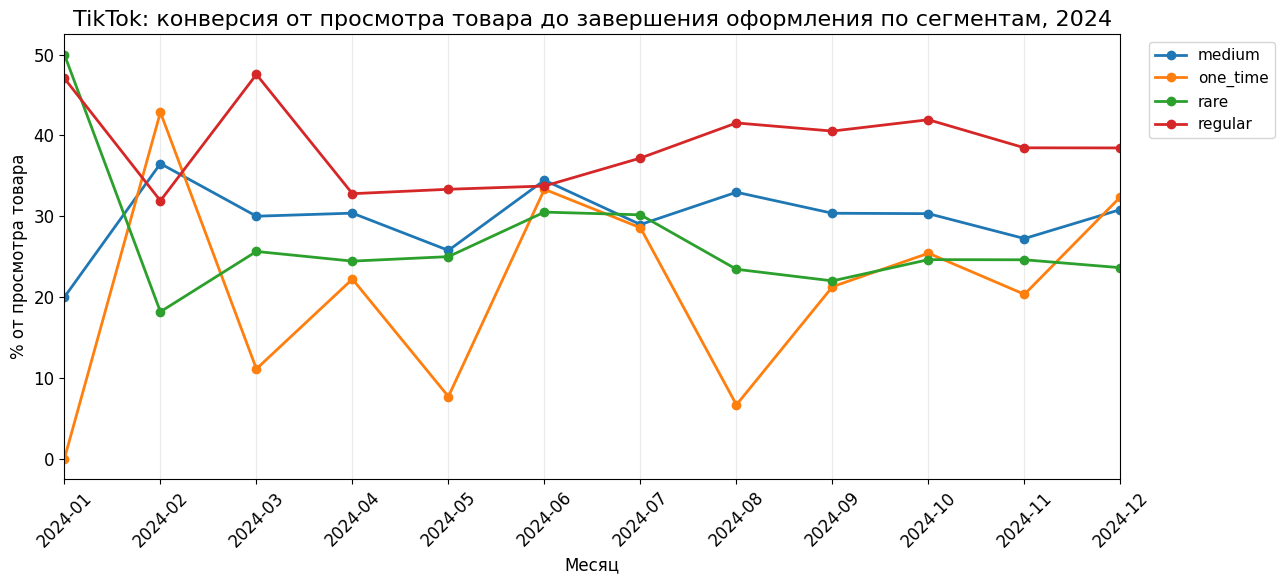

In [31]:
tiktok_flags = funnel_flags[funnel_flags['acq_channel'] == 'TikTok'].copy()

tiktok_funnel = tiktok_flags.groupby(
    ['month', 'buyer_segment']
)[funnel_columns].sum().reset_index()
tiktok_funnel['view_to_complete'] = (
    tiktok_funnel['checkout_complete_step']
    / tiktok_funnel['view_step'] * 100
)
tiktok_funnel['checkout_completion'] = (
    tiktok_funnel['checkout_complete_step']
    / tiktok_funnel['checkout_start_step'] * 100
)
tiktok_funnel = tiktok_funnel.rename(
    columns={'buyer_segment': 'segment'}
)
tiktok_funnel['dimension'] = 'buyer_segment'

plot_monthly(
    tiktok_funnel, 'buyer_segment', 'view_to_complete',
    'TikTok: конверсия от просмотра товара до завершения оформления по сегментам, 2024',
    '% от просмотра товара'
)

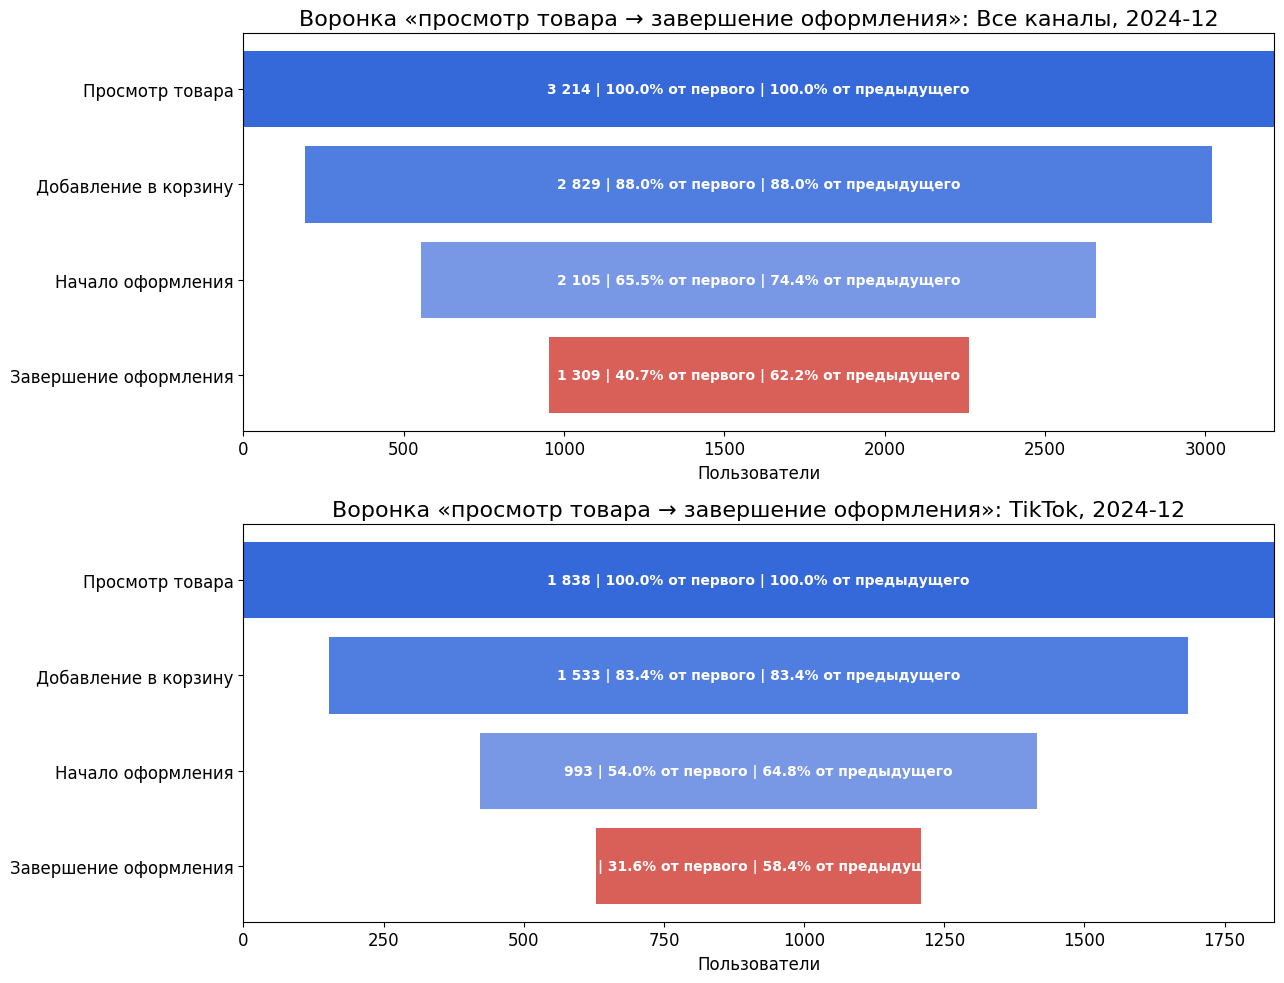

In [32]:
funnel_month = overall_funnel.index.max()
overall_values = overall_funnel.loc[funnel_month]
tiktok_values = tiktok_flags[tiktok_flags['month'] == funnel_month][funnel_columns].sum()
tiktok_values.index = funnel_names

fig, axes = plt.subplots(2, 1, figsize=(13, 10))
for ax, values, title in [(axes[0], overall_values, 'Все каналы'), (axes[1], tiktok_values, 'TikTok')]:
    first_value = values.iloc[0]
    left = (first_value - values) / 2
    ax.barh(funnel_names, values, left=left, color=['#3568d8', '#4f7de0', '#7898e6', '#d95f59'])
    ax.invert_yaxis()
    ax.set_xlim(0, first_value)
    ax.set_title(f'Воронка «просмотр товара → завершение оформления»: {title}, {funnel_month:%Y-%m}')
    ax.set_xlabel('Пользователи')
    ax.grid(False)
    previous_value = first_value
    for position, value in enumerate(values):
        from_first = value / first_value
        from_previous = 1 if position == 0 else value / previous_value
        label = f'{int(value):,} | {from_first:.1%} от первого | {from_previous:.1%} от предыдущего'.replace(',', ' ')
        ax.text(first_value / 2, position, label, ha='center', va='center', color='white', fontweight='bold', fontsize=10)
        previous_value = value
plt.tight_layout()
plt.show()

#### Промежуточный вывод по конверсии и воронке

TikTok стабильно имеет самую низкую конверсию среди каналов: в декабре она составила 7,3%. Рост доли TikTok поэтому снижает общую конверсию. Одновременно показатель падает внутри крупных сегментов: у regular — с 60,6% до 40,4%, у medium — с 30,6% до 18,3%, у rare — с 13,5% до 8,8%.

В декабрьской воронке до завершения оформления дошло 40,7% пользователей, просмотревших товар. Самый слабый переход — из корзины к началу оформления, 74,4%.


### 4.3. Выручка на покупателя (ARPPU)

ARPPU — выручка маркетплейса на одного покупающего пользователя в месяц.

Метрику рассматриваем помесячно по каналам, покупательским сегментам и товарным категориям. На графике категорий показаны пять крупнейших по выручке.

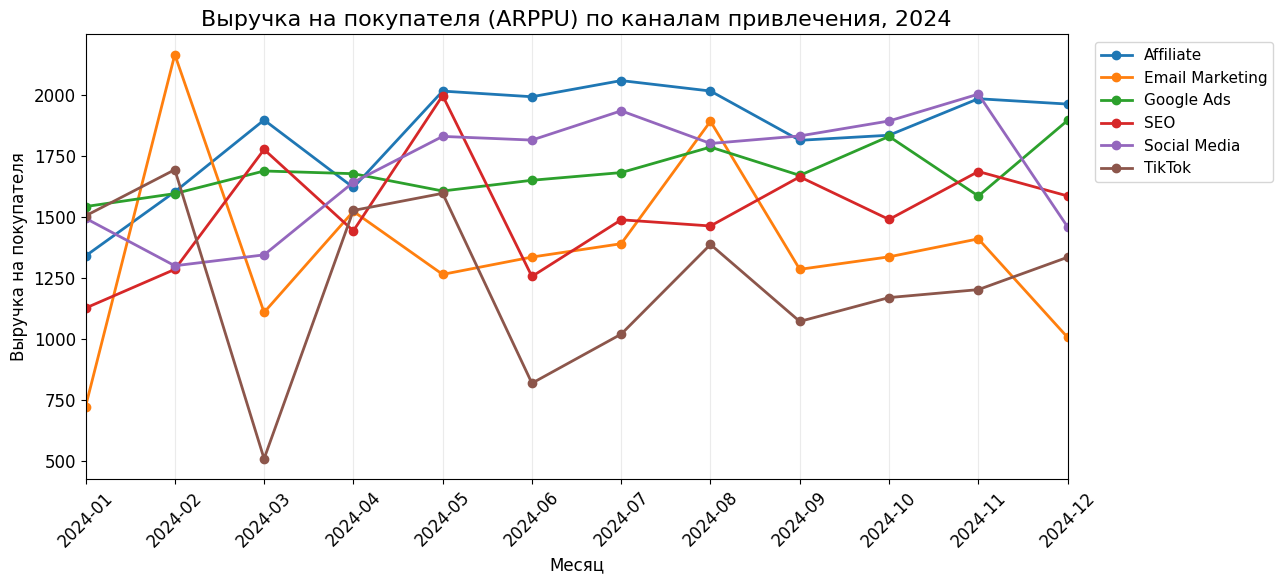

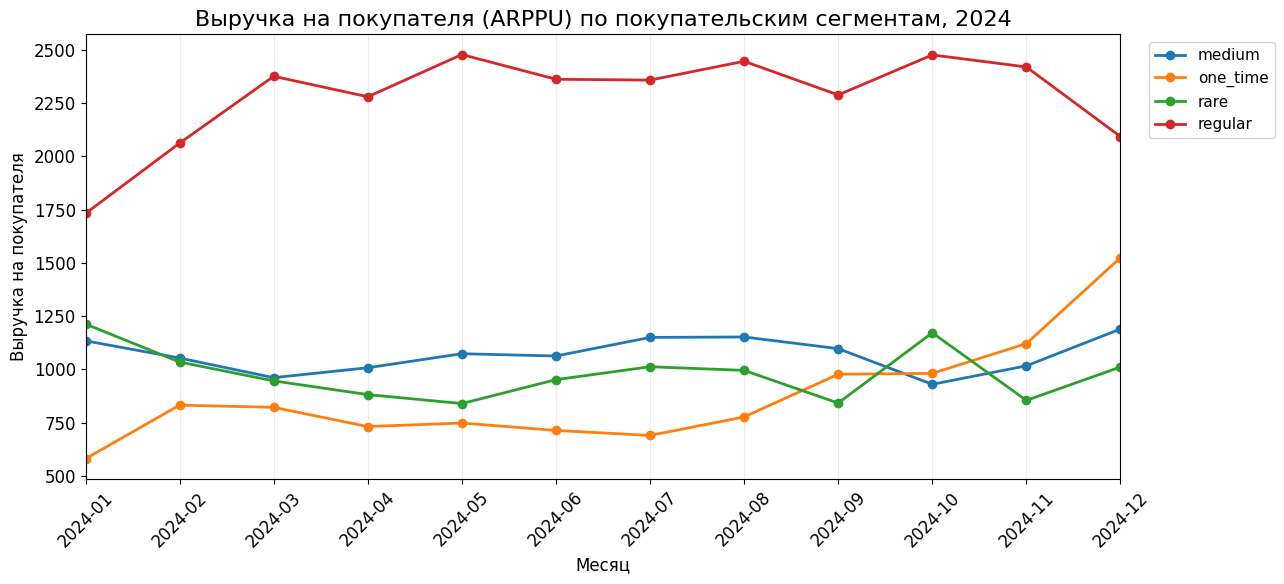

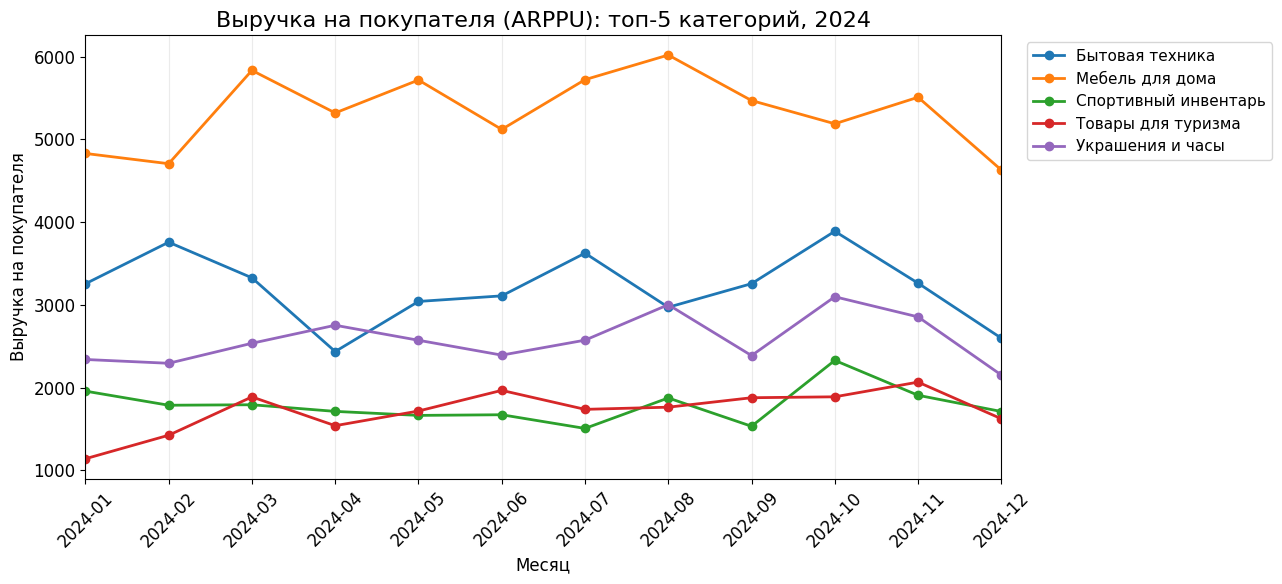

In [33]:
arppu_parts = []
for dimension in ['acq_channel', 'buyer_segment']:
    part = metric_activity.groupby(['month', dimension]).agg(
        buyers=('buyer', 'sum'), revenue=('revenue', 'sum')
    ).reset_index()
    part['arppu'] = part['revenue'] / part['buyers']
    part = part.rename(columns={dimension: 'segment'})
    part['dimension'] = dimension
    arppu_parts.append(part)

category_user_month = pa_marketplace_orders.groupby(
    ['user_id', 'month', 'category_name']
).agg(revenue=('total_price', 'sum')).reset_index()
category_user_month['revenue'] = category_user_month['revenue'] * 0.05
category_arppu = category_user_month.groupby(['month', 'category_name']).agg(
    buyers=('user_id', 'nunique'), revenue=('revenue', 'sum')
).reset_index()
category_arppu['arppu'] = category_arppu['revenue'] / category_arppu['buyers']
category_arppu = category_arppu.rename(columns={'category_name': 'segment'})
category_arppu['dimension'] = 'category_name'
arppu_parts.append(category_arppu)

arppu_by_segment = pd.concat(arppu_parts, ignore_index=True)
top_categories = category_user_month.groupby('category_name')['revenue'].sum().nlargest(5).index
for dimension in ['acq_channel', 'buyer_segment', 'category_name']:
    selected = top_categories if dimension == 'category_name' else None
    chart_title = f"Выручка на покупателя (ARPPU) по {dimension_titles[dimension]}, 2024"
    if dimension == 'category_name':
        chart_title = 'Выручка на покупателя (ARPPU): топ-5 категорий, 2024'
    plot_monthly(
        arppu_by_segment, dimension, 'arppu',
        chart_title, 'Выручка на покупателя', selected
    )

#### Промежуточный вывод по ARPPU

Выручка на покупателя не показывает устойчивого снижения. У medium она изменилась с 1 133,9 в январе до 1 189,4 в декабре, у regular — с 1 732,1 до 2 093,2. Основной разрыв между ARPU и ARPPU создаёт снижение доли покупателей.

### 4.4. Частота покупок

Частота покупок — среднее число заказов на одного покупателя в месяц.

Метрику рассматриваем помесячно по сегментам, каналам и товарным категориям. Для категорий показана пятёрка лидеров по числу заказов.

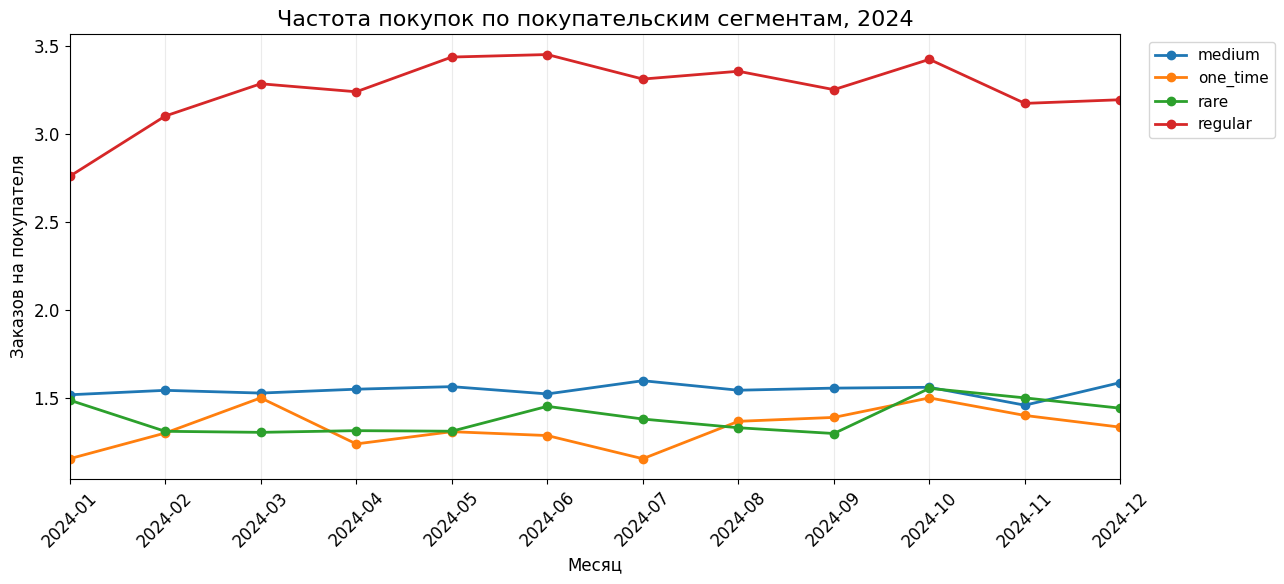

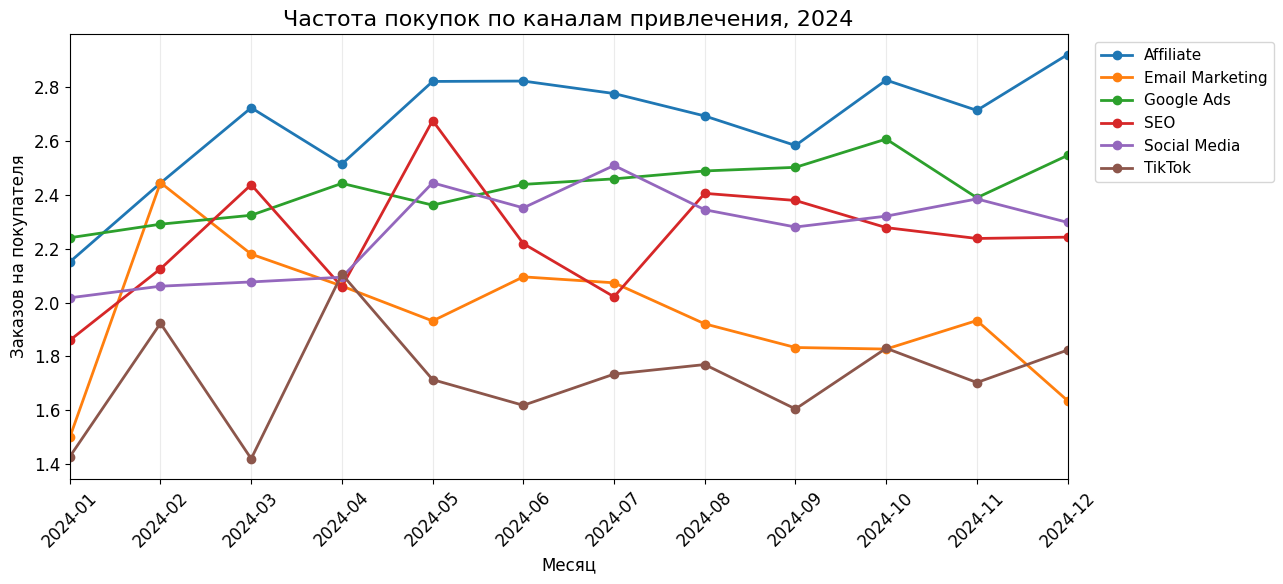

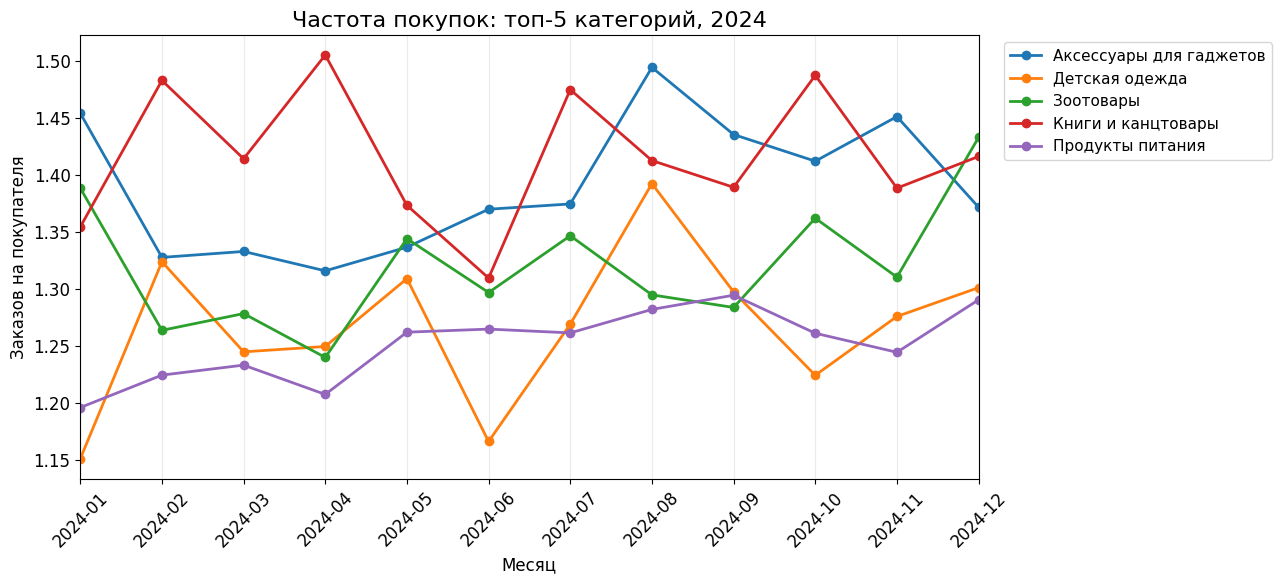

In [34]:
frequency_parts = []
for dimension in ['buyer_segment', 'acq_channel']:
    part = metric_activity.groupby(['month', dimension]).agg(
        buyers=('buyer', 'sum'), orders=('orders', 'sum')
    ).reset_index()
    part['frequency'] = part['orders'] / part['buyers']
    part = part.rename(columns={dimension: 'segment'})
    part['dimension'] = dimension
    frequency_parts.append(part)

category_frequency = pa_marketplace_orders.groupby(
    ['user_id', 'month', 'category_name']
).agg(orders=('order_id', 'nunique')).reset_index()
category_monthly = category_frequency.groupby(['month', 'category_name']).agg(
    buyers=('user_id', 'nunique'), orders=('orders', 'sum')
).reset_index()
category_monthly['frequency'] = category_monthly['orders'] / category_monthly['buyers']
category_monthly = category_monthly.rename(columns={'category_name': 'segment'})
category_monthly['dimension'] = 'category_name'
frequency_parts.append(category_monthly)

frequency_by_segment = pd.concat(frequency_parts, ignore_index=True)
top_order_categories = category_frequency.groupby('category_name')['orders'].sum().nlargest(5).index
for dimension in ['buyer_segment', 'acq_channel', 'category_name']:
    selected = top_order_categories if dimension == 'category_name' else None
    chart_title = f"Частота покупок по {dimension_titles[dimension]}, 2024"
    if dimension == 'category_name':
        chart_title = 'Частота покупок: топ-5 категорий, 2024'
    plot_monthly(
        frequency_by_segment, dimension, 'frequency',
        chart_title, 'Заказов на покупателя', selected
    )

#### Промежуточный вывод по частоте покупок

Частота заказов остаётся стабильной: у medium — около 1,5–1,6 заказа на покупателя, у regular — 3,2–3,4. По каналам и крупнейшим категориям общего нисходящего тренда также нет. Значит, снижение выручки возникает преимущественно до совершения покупки.

### 4.5. Средний чек (AOV)

Средний чек — средний оборот одного заказа.

Метрику рассматриваем помесячно по товарным категориям и покупательским сегментам. Для категорий показана пятёрка лидеров по обороту.

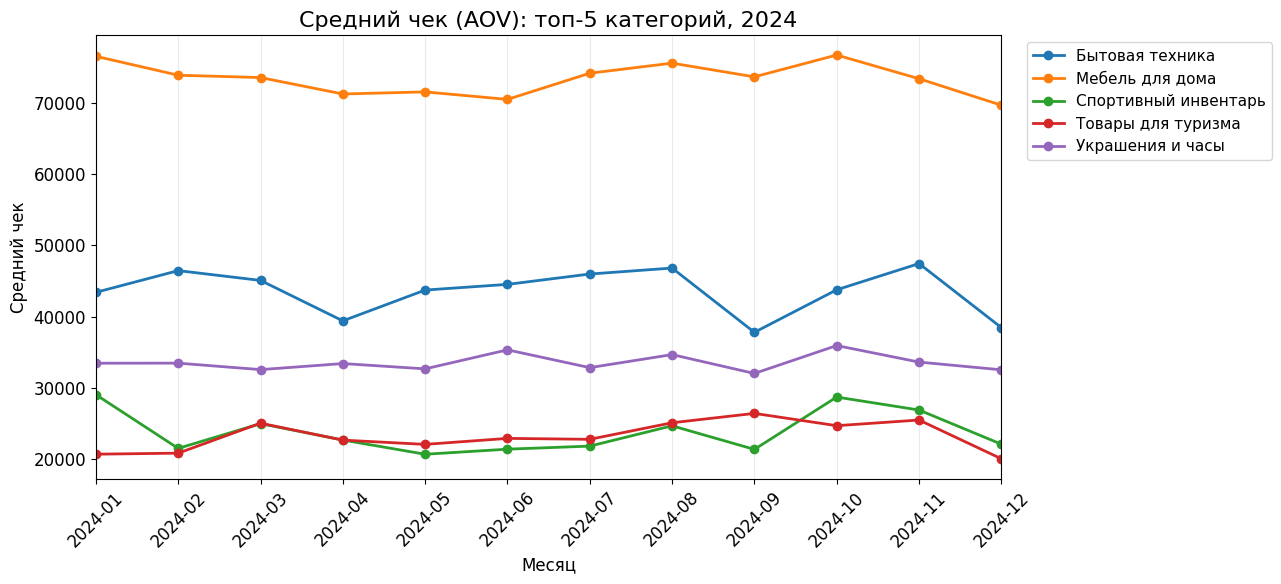

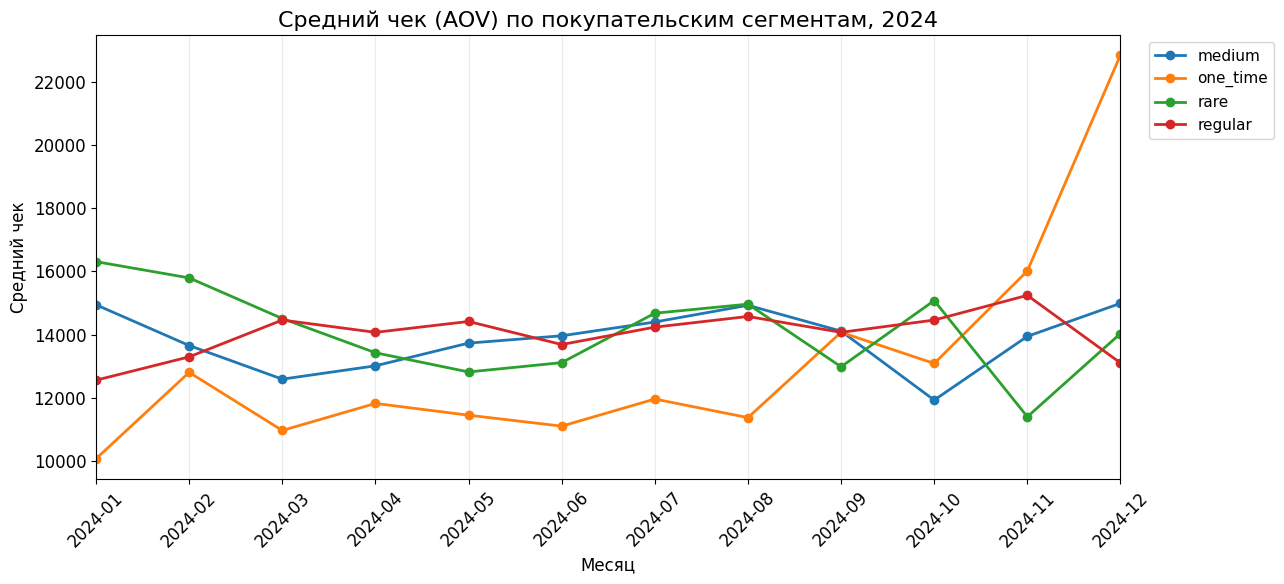

In [35]:
order_segments = pa_marketplace_orders.merge(
    analysis_users[['user_id', 'buyer_segment']],
    on='user_id', how='left'
)
aov_parts = []
for dimension in ['category_name', 'buyer_segment']:
    part = order_segments.groupby(['month', dimension]).agg(
        gmv=('total_price', 'sum'), orders=('order_id', 'nunique')
    ).reset_index()
    part['aov'] = part['gmv'] / part['orders']
    part = part.rename(columns={dimension: 'segment'})
    part['dimension'] = dimension
    aov_parts.append(part)

aov_by_segment = pd.concat(aov_parts, ignore_index=True)
top_gmv_categories = order_segments.groupby('category_name')['total_price'].sum().nlargest(5).index
for dimension in ['category_name', 'buyer_segment']:
    selected = top_gmv_categories if dimension == 'category_name' else None
    chart_title = f"Средний чек (AOV) по {dimension_titles[dimension]}, 2024"
    if dimension == 'category_name':
        chart_title = 'Средний чек (AOV): топ-5 категорий, 2024'
    plot_monthly(
        aov_by_segment, dimension, 'aov',
        chart_title, 'Средний чек', selected
    )

#### Промежуточный вывод по среднему чеку

Средний чек заметно различается между категориями, но не показывает общего устойчивого падения. У medium он составил 14,9 тыс. в январе и 15,0 тыс. в декабре, у regular — 12,6 тыс. и 13,1 тыс. Средний чек не объясняет масштаб снижения ARPU и общей выручки.

### 4.6. Удержание пользователей

Удержание — доля пользователей активного месяца, вернувшихся в следующий календарный месяц.

Метрику рассматриваем помесячно по каналу привлечения, покупательскому сегменту и первому устройству. Декабрь исключён, поскольку для него нет полного следующего месяца наблюдения.

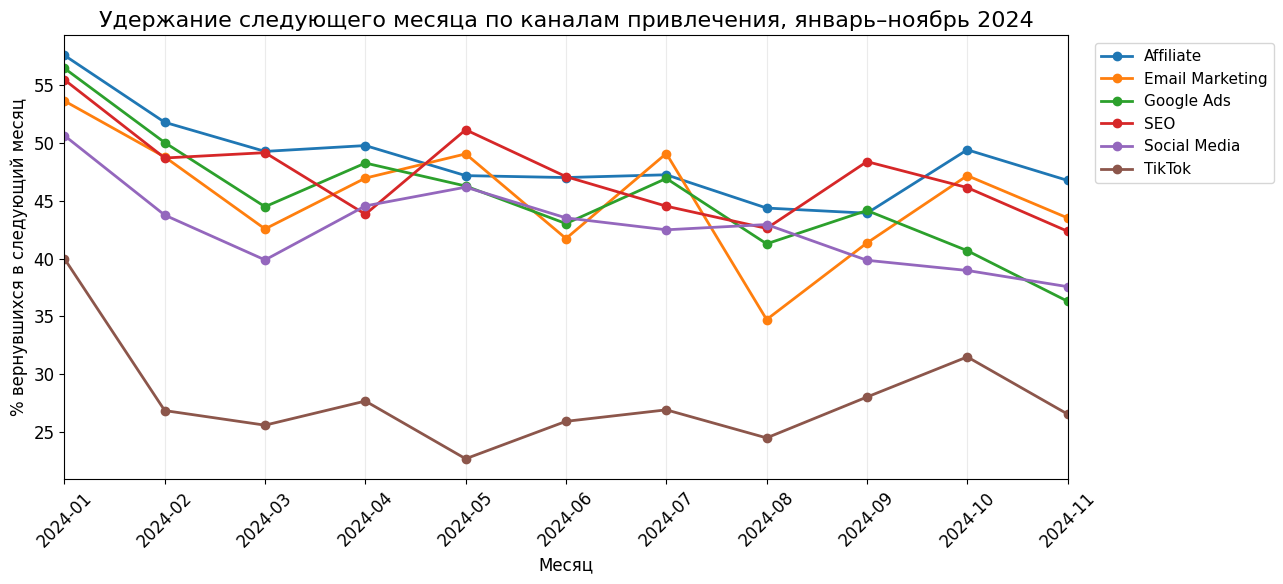

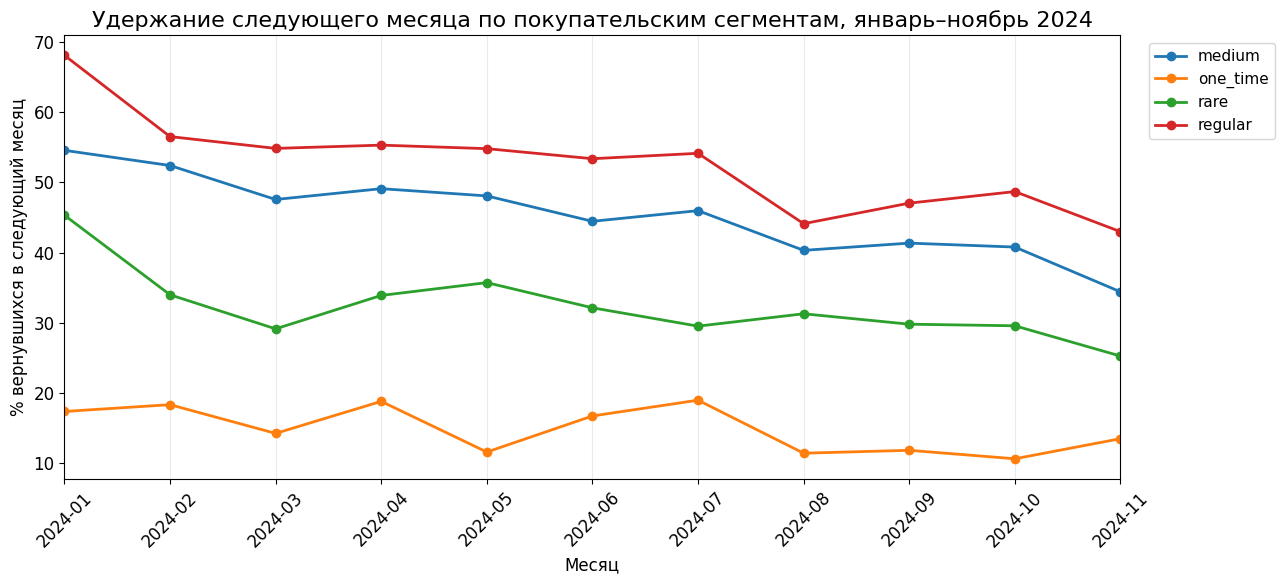

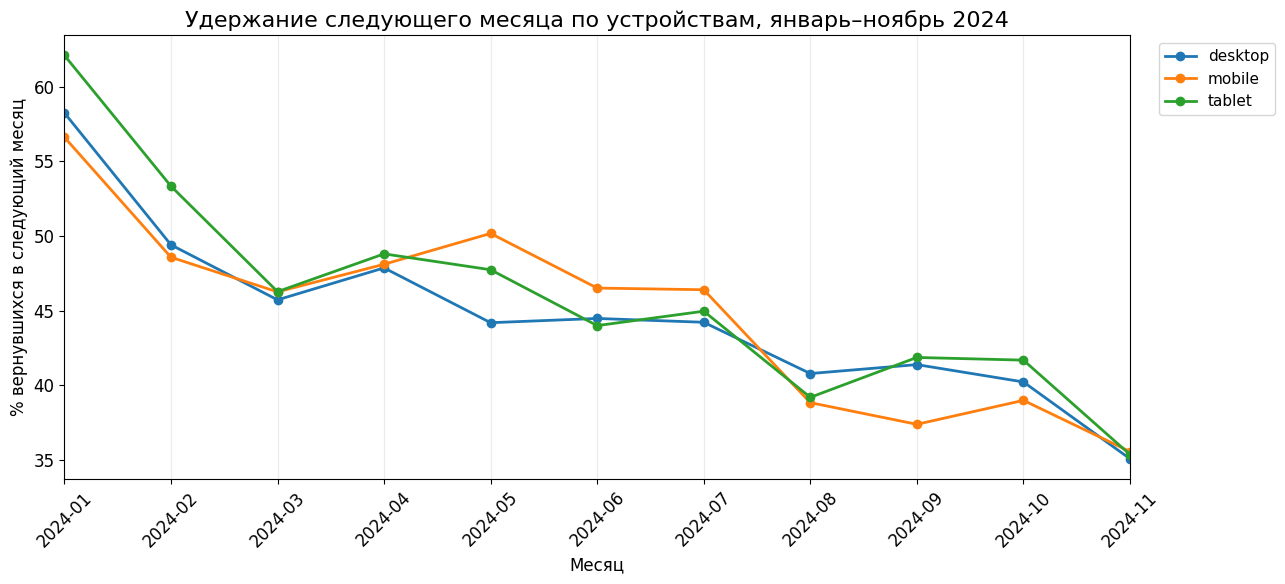

In [36]:
retention_base = monthly_activity[['user_id', 'month']].rename(columns={'month': 'base_month'})
retention_base['next_month'] = retention_base['base_month'] + pd.DateOffset(months=1)
retention_return = monthly_activity[['user_id', 'month']].rename(columns={'month': 'next_month'})
retention_return['retained_next_month'] = 1
retention_data = retention_base.merge(retention_return, on=['user_id', 'next_month'], how='left')
retention_data['retained_next_month'] = retention_data['retained_next_month'].fillna(0)
retention_data = retention_data[retention_data['base_month'] < monthly_activity['month'].max()].copy()
retention_data = retention_data.rename(columns={'base_month': 'month'})

first_device = pa_marketplace_events.sort_values(
    ['user_id', 'event_date', 'event_id']
).drop_duplicates('user_id')[['user_id', 'device']]
retention_data = retention_data.merge(
    analysis_users[['user_id', 'acq_channel', 'buyer_segment']],
    on='user_id', how='left'
).merge(first_device, on='user_id', how='left')

retention_parts = []
retention_dimensions = ['acq_channel', 'buyer_segment', 'device']
for dimension in retention_dimensions:
    part = retention_data.groupby(['month', dimension]).agg(
        base_users=('user_id', 'nunique'), retention=('retained_next_month', 'mean')
    ).reset_index()
    part['retention'] = part['retention'] * 100
    part = part.rename(columns={dimension: 'segment'})
    part['dimension'] = dimension
    retention_parts.append(part)

retention_by_segment = pd.concat(retention_parts, ignore_index=True)
for dimension in retention_dimensions:
    plot_monthly(
        retention_by_segment, dimension, 'retention',
        f"Удержание следующего месяца по {dimension_titles[dimension]}, январь–ноябрь 2024",
        '% вернувшихся в следующий месяц'
    )

#### Промежуточный вывод по удержанию

Удержание снижается в большинстве каналов: с января по ноябрь у Affiliate — с 57,6% до 46,8%, у SEO — с 55,5% до 42,4%, у Social Media — с 50,7% до 37,6%, у TikTok — с 40,0% до 26,5%. У regular показатель снизился с 68,2% до 43,0%, у medium — с 54,6% до 34,4%.

Проблему удержания нельзя объяснить только ростом TikTok. После октября в данных нет новых пользователей Google Ads, поэтому отсутствие поздних точек этого канала не интерпретируется как продуктовый тренд.

### 4.7. Ценность клиента (LTV)

Сравниваем накопленную выручку на пользователя к концу M2 по месяцам привлечения, каналам и покупательским сегментам. Используются когорты января–октября с одинаковым горизонтом M0–M2.

Отношение LTV/CAC дополнительно рассчитывается по платным каналам.

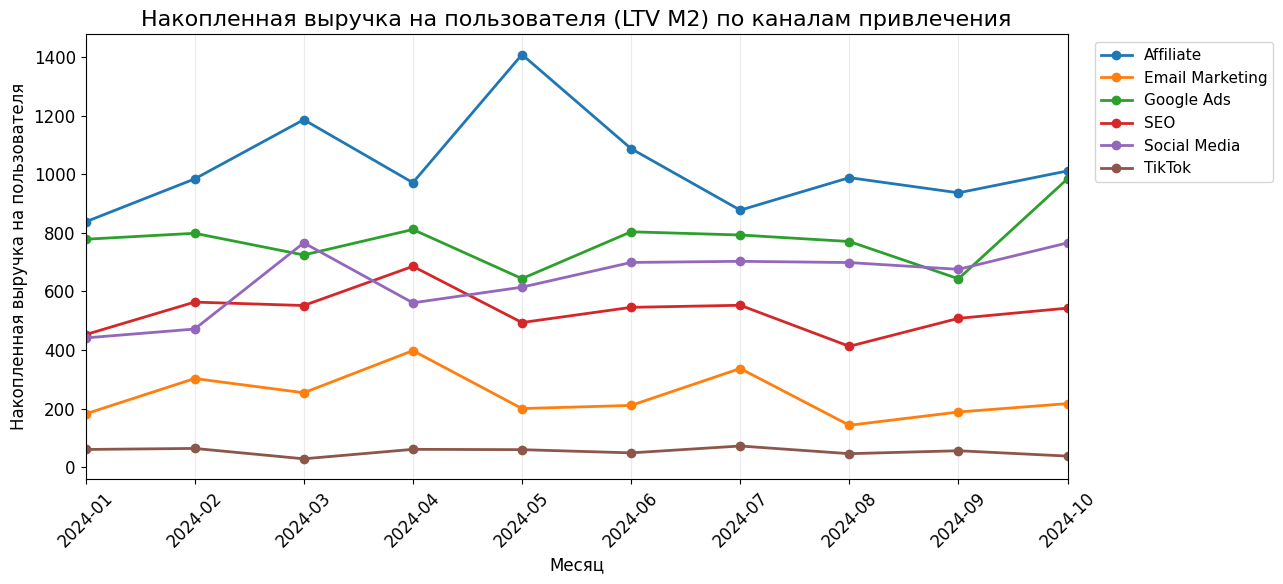

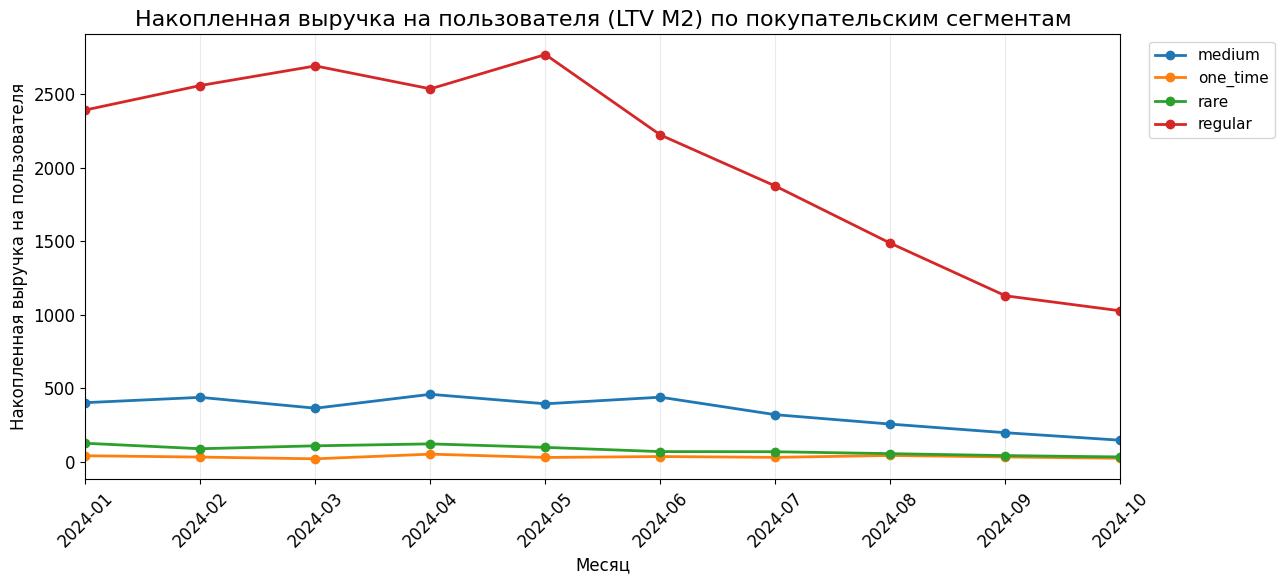

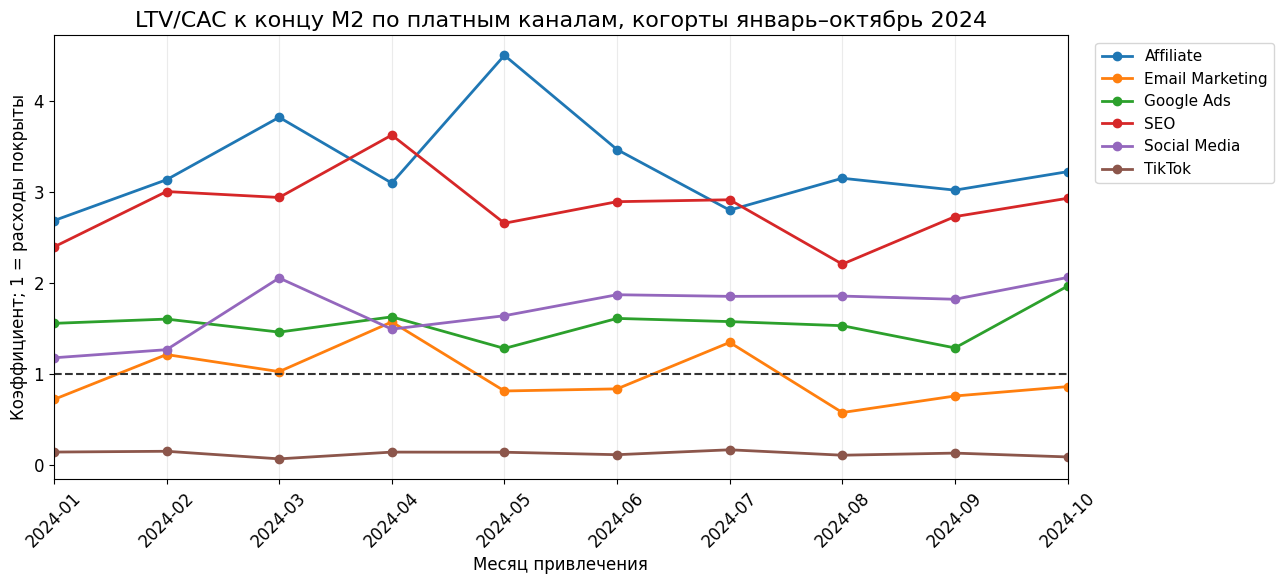

In [37]:
ltv_users = analysis_users[
    analysis_users['cohort_month'].between('2024-01-01', '2024-10-01')
].copy()
ltv_orders = pa_marketplace_orders.merge(
    ltv_users[['user_id', 'cohort_month']], on='user_id', how='inner'
)
ltv_orders['lifetime_month'] = (
    (ltv_orders['month'].dt.year - ltv_orders['cohort_month'].dt.year) * 12
    + ltv_orders['month'].dt.month - ltv_orders['cohort_month'].dt.month
)
ltv_orders = ltv_orders[ltv_orders['lifetime_month'].between(0, 2)].copy()
ltv_orders['revenue'] = ltv_orders['total_price'] * 0.05
user_ltv = ltv_orders.pivot_table(
    index='user_id', columns='lifetime_month', values='revenue',
    aggfunc='sum', fill_value=0
).reindex(columns=[0, 1, 2], fill_value=0)
user_ltv.columns = ['revenue_m0', 'revenue_m1', 'revenue_m2']
user_ltv = user_ltv.reset_index()
ltv_users = ltv_users.merge(user_ltv, on='user_id', how='left')
ltv_users[['revenue_m0', 'revenue_m1', 'revenue_m2']] = ltv_users[['revenue_m0', 'revenue_m1', 'revenue_m2']].fillna(0)
ltv_users['ltv_m2'] = ltv_users[['revenue_m0', 'revenue_m1', 'revenue_m2']].sum(axis=1)

ltv_parts = []
ltv_dimensions = ['acq_channel', 'buyer_segment']
for dimension in ltv_dimensions:
    part = ltv_users.groupby(['cohort_month', dimension]).agg(
        users=('user_id', 'nunique'), ltv_m2=('ltv_m2', 'mean')
    ).reset_index().rename(columns={'cohort_month': 'month', dimension: 'segment'})
    part['dimension'] = dimension
    ltv_parts.append(part)
ltv_by_segment = pd.concat(ltv_parts, ignore_index=True)
for dimension in ltv_dimensions:
    plot_monthly(
        ltv_by_segment, dimension, 'ltv_m2',
        f"Накопленная выручка на пользователя (LTV M2) по {dimension_titles[dimension]}",
        'Накопленная выручка на пользователя'
    )

channel_spend = pa_marketplace_campaign_costs[
    pa_marketplace_campaign_costs['spend_month'].between('2024-01-01', '2024-10-01')
    & (pa_marketplace_campaign_costs['acq_channel'] != 'Direct')
].groupby(['spend_month', 'acq_channel'])['budget'].sum().reset_index(name='spend')
channel_ltv = ltv_users.groupby(['cohort_month', 'acq_channel']).agg(
    users=('user_id', 'nunique'), ltv_m2=('ltv_m2', 'mean')
).reset_index()
channel_ltv = channel_ltv.merge(
    channel_spend, left_on=['cohort_month', 'acq_channel'],
    right_on=['spend_month', 'acq_channel'], how='inner'
)
channel_ltv['cac'] = channel_ltv['spend'] / channel_ltv['users']
channel_ltv['ltv_cac_m2'] = channel_ltv['ltv_m2'] / channel_ltv['cac']
ratio_plot = channel_ltv.pivot(
    index='cohort_month', columns='acq_channel', values='ltv_cac_m2'
).sort_index()
ax = ratio_plot.plot(figsize=(13, 6), marker='o', linewidth=2)
ax.axhline(1, color='#333333', linestyle='--', linewidth=1.5)
ax.set_title('LTV/CAC к концу M2 по платным каналам, когорты январь–октябрь 2024')
ax.set_xlabel('Месяц привлечения')
ax.set_ylabel('Коэффициент; 1 = расходы покрыты')
ax.set_xticks(ratio_plot.index)
ax.set_xticklabels(ratio_plot.index.strftime('%Y-%m'), rotation=45)
ax.legend(title='', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

#### Промежуточный вывод по LTV

Общий LTV M2 снизился с максимума 685,2 у апрельской когорты до 249,4 у октябрьской — на 63,6%. Внутри большинства каналов такого синхронного падения нет.

TikTok сочетает низкий LTV M2 — 28–72 — и LTV/CAC M2 на уровне 0,07–0,16. Email Marketing также часто не покрывает CAC к M2, тогда как Affiliate, SEO и Social Media в основном достигают единицы. После октября новые пользователи Google Ads отсутствуют, поэтому поздние точки для канала недоступны.

## Выводы по этапу 4

Помесячная диагностика выявила два механизма снижения выручки.

Первый — изменение структуры привлечения. Регистрации TikTok выросли с 394 в январе до 3 506 в декабре, при этом канал имеет минимальные ARPU, конверсию и LTV/CAC. Второй — ухудшение поведения действующей аудитории: удержание снизилось почти во всех каналах и устройствах, а конверсия упала внутри крупных сегментов regular и medium.

Выручка на покупателя, частота покупок и средний чек не показывают сопоставимого общего снижения. Значит, основные потери возникают из-за уменьшения доли покупателей и повторной активности.

**Рекомендации и гипотезы**

1. Для TikTok проверить более точный таргетинг и бонус на первую покупку.
2. Для regular и medium протестировать сценарии удержания и реактивации.
3. Проверить этап «корзина → начало оформления»: ошибки, скорость, оплату, доставку и отображение итоговой цены.
4. Перераспределять маркетинговый бюджет только после сравнения конверсии, удержания и LTV/CAC по результатам экспериментов.


## 5. Подготовка эксперимента и подведение его результатов

# Новые вводные (после этапа 4)
Команда продукта рассмотрела твои гипотезы и на основании этого решила влиять на конверсию при помощи финансовых стимуляций. Так как ситуация со снижением выручки срочная и безотлагательная, пока ты продолжал изучать данные, они подключили другого аналитика для подготовки дизайн документа, но само проведение эксперимента на тебе.


При формировании выводов допиши рекомендации по итогам теста и, если необходимо, опиши проблемы, присутствующие в эксперименте.


## Новые данные:
```python
pa_marketplace_events_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_events_AB.csv')
pa_marketplace_orders_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_orders_AB.csv')
pa_marketplace_users_AB = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_users_AB.csv')
```
## Результаты сплита лежат в таблице:
```python
pa_marketplace_AB_split_users = pd.read_csv('https://code.s3.yandex.net/datasets/pa_marketplace_AB_split_users.csv')
```
* user_id – id клиента
* group – группа, в которую попал клиент


# Дизайн эксперимента: Бонус на первую покупку для пользователей TikTok
## 1. Контекст и цель эксперимента
- **Бизнес-контекст:** Команда продукта запускает эксперимент, направленный на повышение конверсии среди пользователей, привлечённых через канал TikTok. Для стимулирования первой покупки пользователям будет предоставлен бонус на первую покупку.
- **Цель:** Проверить, влияет ли предоставление бонуса на первую покупку на конверсию и выручку среди пользователей TikTok.
- **Гипотеза:** Предоставление бонуса на первую покупку новым пользователям, привлеченным через TikTok, приведет к увеличению конверсии в первую покупку
---
## 2. Формат эксперимента
- **Тип эксперимента:** Сплит-роллинг (rolling split)
- **Канал:** Только пользователи, пришедшие с TikTok
- **Группы:**
    - **Контрольная (A):** пользователи TikTok без бонуса
    - **Тестовая (B):** пользователи TikTok с бонусом на первую покупку
- **Распределение:** Равномерное распределение новых пользователей TikTok между группами по дате регистрации
- **Период проведения:** 3 недели (фиксировано)
---
## 3. Ключевые метрики
### Основная метрика
- **Конверсия в первую покупку** — доля пользователей, зарегистрировавшихся с TikTok и совершивших первую покупку
- *Цель:* увеличить конверсию с помощью бонуса
- *Критерий успеха:* статистически значимый рост конверсии в тестовой группе
### Вспомогательные метрики
- **ARPU** (средняя выручка на пользователя TikTok)
- **ARPPU** (средняя выручка на покупателя TikTok)
- **AOV** (средний чек TikTok)
### Барьерная метрика
- **Общая выручка от пользователей TikTok**
---
## 4. Размеры групп и запуск
- **Целевая аудитория:** только пользователи TikTok
- **Размеры групп:** определяются по фактическому трафику TikTok за период эксперимента
- **Комментарий:** запуск без предварительного расчёта мощности и MDE из-за срочности задачи


In [38]:
import numpy as np
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import (
    confint_proportions_2indep,
    proportions_ztest
)

ab_base_url = 'https://code.s3.yandex.net/datasets/'

pa_marketplace_events_AB = pd.read_csv(
    ab_base_url + 'pa_marketplace_events_AB.csv',
    parse_dates=['event_date']
)
pa_marketplace_orders_AB = pd.read_csv(
    ab_base_url + 'pa_marketplace_orders_AB.csv',
    parse_dates=['order_date']
)
pa_marketplace_users_AB = pd.read_csv(
    ab_base_url + 'pa_marketplace_users_AB.csv',
    parse_dates=['registration_date']
)
pa_marketplace_AB_split_users = pd.read_csv(
    ab_base_url + 'pa_marketplace_AB_split_users.csv'
)

ab_table_sizes = pd.DataFrame({
    'Таблица': ['События', 'Заказы', 'Пользователи', 'Сплит'],
    'Строки': [
        len(pa_marketplace_events_AB),
        len(pa_marketplace_orders_AB),
        len(pa_marketplace_users_AB),
        len(pa_marketplace_AB_split_users)
    ],
    'Столбцы': [
        pa_marketplace_events_AB.shape[1],
        pa_marketplace_orders_AB.shape[1],
        pa_marketplace_users_AB.shape[1],
        pa_marketplace_AB_split_users.shape[1]
    ]
})

print('Размеры таблиц A/B-теста')
display(ab_table_sizes)

Размеры таблиц A/B-теста


,Таблица,Строки,Столбцы
0,События,831231,9
1,Заказы,33280,10
2,Пользователи,22196,9
3,Сплит,2968,2


### 5.1. Протокол анализа эксперимента

До расчёта эффекта фиксируем правила анализа:

- единица анализа — пользователь из таблицы сплита;
- подход — ITT: в расчёт входят все распределённые пользователи в назначенных группах;
- период наблюдения заканчивается в момент завершения эксперимента;
- результаты статистических тестов проверяются один раз — после полного завершения эксперимента;
- уровень значимости — α = 0,05, проверки двусторонние;
- мощность для предварительной оценки MDE — 80%;
- основное решение принимается по конверсии в первую покупку;
- ARPU, ARPPU и AOV являются вспомогательными метриками;
- для вспомогательных тестов применяется поправка Холма;
- региональные разрезы не используются.

Промежуточные p-value и тесты по отдельным горизонтам не рассчитываются. Сначала оцениваем чувствительность дизайна, затем — только на полностью собранных данных — рассчитываем итоговый эффект.

In [39]:
ab_tables = {
    'События': pa_marketplace_events_AB,
    'Заказы': pa_marketplace_orders_AB,
    'Пользователи': pa_marketplace_users_AB,
    'Сплит': pa_marketplace_AB_split_users
}

data_quality_rows = []
for table_name, table in ab_tables.items():
    data_quality_rows.append({
        'Таблица': table_name,
        'Строки': len(table),
        'Полные дубликаты': table.duplicated().sum()
    })

data_quality = pd.DataFrame(data_quality_rows)
print('Качество данных A/B-теста')
display(data_quality)

experiment_profiles = pa_marketplace_AB_split_users.merge(
    pa_marketplace_users_AB,
    on='user_id',
    how='left',
    validate='one_to_one'
)

user_group_count = pa_marketplace_AB_split_users.groupby(
    'user_id'
)['group'].nunique()
users_in_both_groups = (user_group_count > 1).sum()
missing_profiles = experiment_profiles['registration_date'].isna().sum()
non_tiktok_users = (
    experiment_profiles['acq_channel'].ne('TikTok').sum()
)

experiment_events = pa_marketplace_events_AB.merge(
    experiment_profiles[['user_id', 'registration_date']],
    on='user_id',
    how='inner'
)
experiment_orders = pa_marketplace_orders_AB.merge(
    experiment_profiles[['user_id', 'registration_date']],
    on='user_id',
    how='inner'
)

events_before_registration = (
    experiment_events['event_date']
    < experiment_events['registration_date']
).sum()
orders_before_registration = (
    experiment_orders['order_date']
    < experiment_orders['registration_date']
).sum()

print('Период регистрации участников:',
      experiment_profiles['registration_date'].min(), '—',
      experiment_profiles['registration_date'].max())
print('Продолжительность набора, дней:',
      experiment_profiles['registration_date'].dt.date.nunique())
print('Пользователи в обеих группах:', users_in_both_groups)
print('Участники без профиля:', missing_profiles)
print('Участники не из TikTok:', non_tiktok_users)
print('События раньше регистрации:', events_before_registration)
print('Заказы раньше регистрации:', orders_before_registration)

Качество данных A/B-теста


,Таблица,Строки,Полные дубликаты
0,События,831231,0
1,Заказы,33280,0
2,Пользователи,22196,0
3,Сплит,2968,0


Период регистрации участников: 2025-01-01 00:05:00 — 2025-01-26 23:41:00
Продолжительность набора, дней: 26
Пользователи в обеих группах: 0
Участники без профиля: 0
Участники не из TikTok: 0
События раньше регистрации: 8
Заказы раньше регистрации: 0


Размер групп


,Пользователи
Группа,
Контрольная,1503
Тестовая,1465


Проверка баланса групп


,Проверка,p-value
0,SRM 50/50,0.4855
1,Распределение по дням,0.1402
2,Пол,0.1485
3,Возраст,0.2973


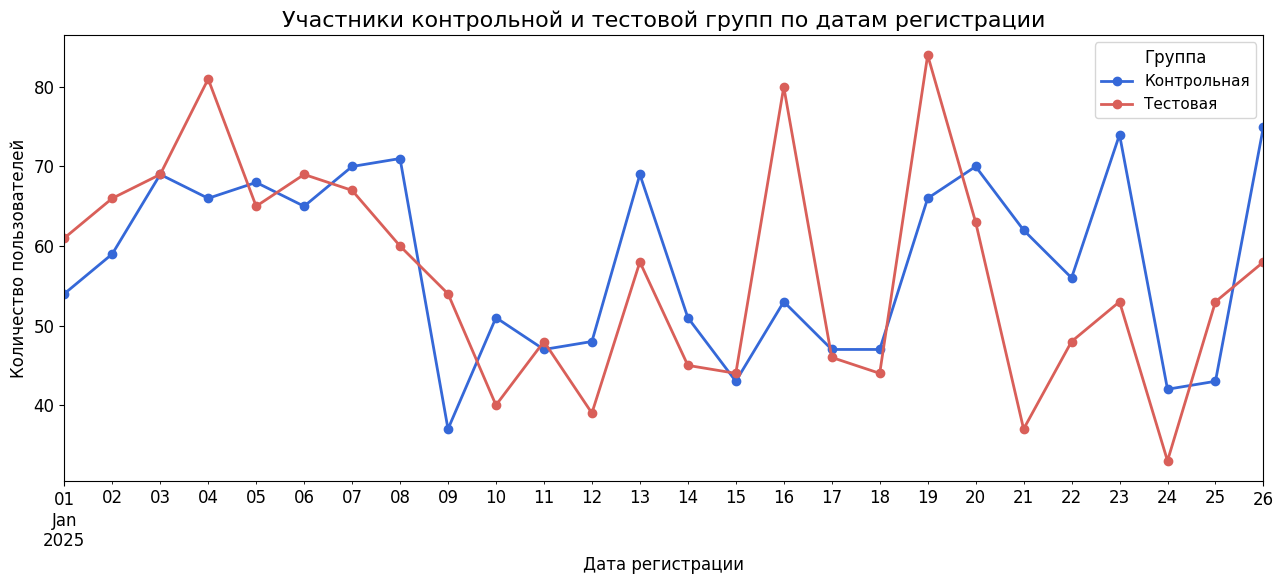

Конец эксперимента: 2025-01-26 23:59:34


In [40]:
group_sizes = experiment_profiles['group'].value_counts().sort_index()
expected_sizes = np.repeat(len(experiment_profiles) / 2, 2)
srm_stat, srm_pvalue = stats.chisquare(
    group_sizes.values,
    expected_sizes
)

daily_split = pd.crosstab(
    experiment_profiles['registration_date'].dt.floor('D'),
    experiment_profiles['group']
)
daily_stat, daily_pvalue, _, _ = stats.chi2_contingency(daily_split)

gender_balance = pd.crosstab(
    experiment_profiles['gender'],
    experiment_profiles['group']
)
gender_stat, gender_pvalue, _, _ = stats.chi2_contingency(
    gender_balance
)

age_control = experiment_profiles.loc[
    experiment_profiles['group'] == 'control', 'age'
]
age_treatment = experiment_profiles.loc[
    experiment_profiles['group'] == 'treatment', 'age'
]
age_pvalue = stats.ttest_ind(
    age_treatment,
    age_control,
    equal_var=False
).pvalue

balance_tests = pd.DataFrame({
    'Проверка': [
        'SRM 50/50',
        'Распределение по дням',
        'Пол',
        'Возраст'
    ],
    'p-value': [
        srm_pvalue,
        daily_pvalue,
        gender_pvalue,
        age_pvalue
    ]
})
group_sizes_display = group_sizes.rename(index={
    'control': 'Контрольная',
    'treatment': 'Тестовая'
}).to_frame('Пользователи')
group_sizes_display.index.name = 'Группа'

print('Размер групп')
display(group_sizes_display)
print('Проверка баланса групп')
display(balance_tests.round(4))

daily_split_plot = daily_split.rename(columns={
    'control': 'Контрольная',
    'treatment': 'Тестовая'
})
ax = daily_split_plot.plot(
    figsize=(13, 6),
    marker='o',
    linewidth=2,
    color=['#3568d8', '#d95f59']
)
ax.set_title('Участники контрольной и тестовой групп по датам регистрации')
ax.set_xlabel('Дата регистрации')
ax.set_ylabel('Количество пользователей')
ax.legend(title='Группа')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

experiment_end = max(
    pa_marketplace_events_AB['event_date'].max(),
    pa_marketplace_orders_AB['order_date'].max()
)

print('Конец эксперимента:', experiment_end)

In [41]:
experiment_start = experiment_profiles['registration_date'].min()
design_horizon_days = 21
historical_cutoff = (
    experiment_start - pd.Timedelta(days=design_horizon_days)
)
historical_users = pa_marketplace_users_AB[
    pa_marketplace_users_AB['registration_date'] <= historical_cutoff
][['user_id', 'registration_date']].copy()

historical_orders = pa_marketplace_orders_AB.merge(
    historical_users,
    on='user_id',
    how='inner'
)
historical_orders = historical_orders[
    (historical_orders['order_date'] >= historical_orders['registration_date'])
    & (
        historical_orders['order_date']
        < historical_orders['registration_date']
        + pd.Timedelta(days=design_horizon_days)
    )
]
historical_buyers = set(historical_orders['user_id'])
historical_conversion = historical_users['user_id'].isin(
    historical_buyers
).mean()

n_control = group_sizes.loc['control']
n_treatment = group_sizes.loc['treatment']
ratio = n_treatment / n_control

mde_effect_size = NormalIndPower().solve_power(
    effect_size=None,
    nobs1=n_control,
    alpha=0.05,
    power=0.80,
    ratio=ratio,
    alternative='two-sided'
)
mde_conversion = np.sin(
    np.arcsin(np.sqrt(historical_conversion))
    + abs(mde_effect_size) / 2
) ** 2
mde_pp = (mde_conversion - historical_conversion) * 100

print(
    f'Историческая конверсия TikTok за {design_horizon_days} день: '
    f'{historical_conversion:.2%}'
)
print(f'Размеры групп: контрольная={n_control}, тестовая={n_treatment}')
print(f'Минимальный обнаруживаемый эффект (MDE): {mde_pp:.2f} п.п.')
print(f'Эксперимент способен обнаружить рост примерно до {mde_conversion:.2%}')

Историческая конверсия TikTok за 21 день: 2.24%
Размеры групп: контрольная=1503, тестовая=1465
Минимальный обнаруживаемый эффект (MDE): 1.77 п.п.
Эксперимент способен обнаружить рост примерно до 4.01%


### 5.2. Метрики и статистические гипотезы

**Основная метрика — конверсия в первую покупку за весь завершённый эксперимент**

- **H₀:** конверсия одинакова в тестовой и контрольной группах.
- **H₁:** конверсии различаются.

**Выручка на пользователя (ARPU)**

- **H₀:** средняя выручка на пользователя одинакова в группах.
- **H₁:** средние значения различаются.

**Выручка на покупателя (ARPPU)**

- **H₀:** средняя выручка на покупателя одинакова в группах.
- **H₁:** средние значения различаются.

**Средний чек (AOV)**

- **H₀:** средний чек одинаков в группах.
- **H₁:** средние значения различаются.

Для конверсии используется тест долей и 95%-й доверительный интервал разницы. Для денежных метрик — тест Уэлча и пользовательский бутстрэп. ARPPU и AOV рассчитываются только среди покупателей и являются вспомогательными показателями.

Общая выручка показывается отдельно, но не тестируется как независимая пользовательская метрика. Без стоимости бонусов нельзя рассчитать чистый финансовый эффект.

In [42]:
analysis_orders = pa_marketplace_orders_AB.merge(
    experiment_profiles[[
        'user_id', 'group', 'registration_date'
    ]],
    on='user_id',
    how='inner'
)
analysis_orders = analysis_orders[
    (analysis_orders['order_date'] >= analysis_orders['registration_date'])
    & (analysis_orders['order_date'] <= experiment_end)
].copy()
analysis_orders['revenue'] = analysis_orders['total_price'] * 0.05

user_orders = analysis_orders.groupby('user_id').agg(
    gmv=('total_price', 'sum'),
    revenue=('revenue', 'sum'),
    orders=('order_id', 'nunique')
).reset_index()

analysis_data = experiment_profiles.merge(
    user_orders,
    on='user_id',
    how='left'
)
analysis_data[['gmv', 'revenue', 'orders']] = (
    analysis_data[['gmv', 'revenue', 'orders']].fillna(0)
)
analysis_data['buyer'] = (analysis_data['orders'] > 0).astype(int)
analysis_data['user_aov'] = np.where(
    analysis_data['orders'] > 0,
    analysis_data['gmv'] / analysis_data['orders'],
    np.nan
)

print('Пользователей в итоговой аналитической витрине:', len(analysis_data))
print('Период регистрации участников:',
      analysis_data['registration_date'].min(), '—',
      analysis_data['registration_date'].max())
print('Наблюдения учтены по:', experiment_end)

Пользователей в итоговой аналитической витрине: 2968
Период регистрации участников: 2025-01-01 00:05:00 — 2025-01-26 23:41:00
Наблюдения учтены по: 2025-01-26 23:59:34


In [43]:
group_metrics = analysis_data.groupby('group').agg(
    users=('user_id', 'nunique'),
    buyers=('buyer', 'sum'),
    conversion=('buyer', 'mean'),
    orders=('orders', 'sum'),
    gmv=('gmv', 'sum'),
    revenue=('revenue', 'sum'),
    arpu=('revenue', 'mean')
)

arppu = analysis_data[analysis_data['buyer'] == 1].groupby(
    'group'
)['revenue'].mean()
aov = analysis_data[analysis_data['buyer'] == 1].groupby(
    'group'
)['user_aov'].mean()

group_metrics['arppu'] = arppu
group_metrics['aov'] = aov
group_metrics['conversion_percent'] = (
    group_metrics['conversion'] * 100
)



group_metrics_display = group_metrics[[
    'users', 'buyers', 'conversion_percent',
    'arpu', 'arppu', 'aov', 'revenue'
]].rename(
    index={
        'control': 'Контрольная',
        'treatment': 'Тестовая'
    },
    columns={
        'users': 'Пользователи',
        'buyers': 'Покупатели',
        'conversion_percent': 'Конверсия, %',
        'arpu': 'Выручка на пользователя (ARPU)',
        'arppu': 'Выручка на покупателя (ARPPU)',
        'aov': 'Средний чек (AOV)',
        'revenue': 'Общая выручка'
    }
)

print('Метрики эксперимента по группам')
display(group_metrics_display.round(2))

Метрики эксперимента по группам


,Пользователи,Покупатели,"Конверсия, %",Выручка на пользователя (ARPU),Выручка на покупателя (ARPPU),Средний чек (AOV),Общая выручка
group,,,,,,,
Контрольная,1503,16,1.06,12.59,1182.42,19188.07,18918.64
Тестовая,1465,110,7.51,131.25,1748.00,16539.64,192279.85


In [44]:
control_buyers = group_metrics.loc['control', 'buyers']
treatment_buyers = group_metrics.loc['treatment', 'buyers']
control_users = group_metrics.loc['control', 'users']
treatment_users = group_metrics.loc['treatment', 'users']

primary_statistic, primary_pvalue = proportions_ztest(
    [treatment_buyers, control_buyers],
    [treatment_users, control_users]
)
primary_ci_low, primary_ci_high = confint_proportions_2indep(
    treatment_buyers,
    treatment_users,
    control_buyers,
    control_users,
    method='newcomb',
    compare='diff'
)
primary_difference = (
    group_metrics.loc['treatment', 'conversion']
    - group_metrics.loc['control', 'conversion']
)
primary_relative_lift = (
    group_metrics.loc['treatment', 'conversion']
    / group_metrics.loc['control', 'conversion'] - 1
)

primary_result = pd.DataFrame({
    'metric': ['CR в первую покупку'],
    'control': [group_metrics.loc['control', 'conversion_percent']],
    'treatment': [group_metrics.loc['treatment', 'conversion_percent']],
    'difference_pp': [primary_difference * 100],
    'relative_lift_percent': [primary_relative_lift * 100],
    'ci_low_pp': [primary_ci_low * 100],
    'ci_high_pp': [primary_ci_high * 100],
    'p_value': [primary_pvalue],
    'significant': [primary_pvalue < 0.05]
})

primary_display = primary_result[[
    'metric', 'control', 'treatment', 'difference_pp',
    'relative_lift_percent', 'p_value', 'significant'
]].copy()
primary_display['95% ДИ разницы, п.п.'] = primary_result.apply(
    lambda row: (
        f'[{row["ci_low_pp"]:.2f}; '
        f'{row["ci_high_pp"]:.2f}]'
    ),
    axis=1
)
primary_display = primary_display.rename(columns={
    'metric': 'Метрика',
    'control': 'Контрольная, %',
    'treatment': 'Тестовая, %',
    'difference_pp': 'Разница, п.п.',
    'relative_lift_percent': 'Изменение, %',
    'p_value': 'p-value',
    'significant': 'Значимо'
})
primary_display['Метрика'] = 'Конверсия в первую покупку'
primary_display['p-value'] = primary_display['p-value'].map(
    lambda value: f'{value:.3g}'
)
primary_display['Значимо'] = primary_display['Значимо'].map({
    True: 'Да',
    False: 'Нет'
})

print('Результат проверки основной метрики')
display(primary_display.round(2))

Результат проверки основной метрики


,Метрика,"Контрольная, %","Тестовая, %","Разница, п.п.","Изменение, %",p-value,Значимо,"95% ДИ разницы, п.п."
0,Конверсия в первую покупку,1.06,7.51,6.44,605.33,3.16e-18,Да,[5.04; 7.96]


In [45]:
rng = np.random.default_rng(341)
bootstrap_iterations = 5000
auxiliary_rows = []

auxiliary_specs = [
    ('ARPU', 'revenue', False),
    ('ARPPU', 'revenue', True),
    ('AOV', 'user_aov', True)
]

for metric_name, column_name, buyers_only in auxiliary_specs:
    metric_data = analysis_data.copy()
    if buyers_only:
        metric_data = metric_data[metric_data['buyer'] == 1]

    control_values = metric_data.loc[
        metric_data['group'] == 'control', column_name
    ].dropna().to_numpy()
    treatment_values = metric_data.loc[
        metric_data['group'] == 'treatment', column_name
    ].dropna().to_numpy()

    differences = np.empty(bootstrap_iterations)
    for iteration in range(bootstrap_iterations):
        boot_control = rng.choice(
            control_values,
            size=len(control_values),
            replace=True
        )
        boot_treatment = rng.choice(
            treatment_values,
            size=len(treatment_values),
            replace=True
        )
        differences[iteration] = (
            boot_treatment.mean() - boot_control.mean()
        )

    ci_low, ci_high = np.percentile(differences, [2.5, 97.5])
    welch_pvalue = stats.ttest_ind(
        treatment_values,
        control_values,
        equal_var=False
    ).pvalue

    auxiliary_rows.append({
        'metric': metric_name,
        'control': control_values.mean(),
        'treatment': treatment_values.mean(),
        'difference': treatment_values.mean() - control_values.mean(),
        'relative_lift_percent': (
            treatment_values.mean() / control_values.mean() - 1
        ) * 100,
        'ci_low': ci_low,
        'ci_high': ci_high,
        'control_std': control_values.std(ddof=1),
        'treatment_std': treatment_values.std(ddof=1),
        'p_value': welch_pvalue
    })

auxiliary_results = pd.DataFrame(auxiliary_rows)
auxiliary_results['p_value_holm'] = multipletests(
    auxiliary_results['p_value'],
    method='holm'
)[1]
auxiliary_results['significant_holm'] = (
    auxiliary_results['p_value_holm'] < 0.05
)

metric_names = {
    'ARPU': 'Выручка на пользователя (ARPU)',
    'ARPPU': 'Выручка на покупателя (ARPPU)',
    'AOV': 'Средний чек (AOV)'
}
auxiliary_display = auxiliary_results[[
    'metric', 'control', 'treatment', 'difference',
    'relative_lift_percent', 'p_value_holm',
    'significant_holm'
]].copy()
auxiliary_display['95% ДИ разницы'] = auxiliary_results.apply(
    lambda row: (
        f'[{row["ci_low"]:.2f}; '
        f'{row["ci_high"]:.2f}]'
    ),
    axis=1
)
auxiliary_display['metric'] = auxiliary_display['metric'].map(
    metric_names
)
auxiliary_display = auxiliary_display.rename(columns={
    'metric': 'Метрика',
    'control': 'Контрольная',
    'treatment': 'Тестовая',
    'difference': 'Разница',
    'relative_lift_percent': 'Изменение, %',
    'p_value_holm': 'p-value Холма',
    'significant_holm': 'Значимо'
})
auxiliary_display['p-value Холма'] = (
    auxiliary_display['p-value Холма'].map(
        lambda value: f'{value:.3g}'
    )
)
auxiliary_display['Значимо'] = auxiliary_display['Значимо'].map({
    True: 'Да',
    False: 'Нет'
})

print('Результаты проверки вспомогательных метрик')
display(auxiliary_display.round(2))

Результаты проверки вспомогательных метрик


,Метрика,Контрольная,Тестовая,Разница,"Изменение, %",p-value Холма,Значимо,95% ДИ разницы
0,Выручка на пользователя (ARPU),12.59,131.25,118.66,942.71,1.23e-08,Да,[81.78; 159.14]
1,Выручка на покупателя (ARPPU),1182.42,1748.00,565.58,47.83,0.0986,Нет,[24.37; 1114.50]
2,Средний чек (AOV),19188.07,16539.64,-2648.42,-13.80,0.542,Нет,[-11184.47; 5087.27]


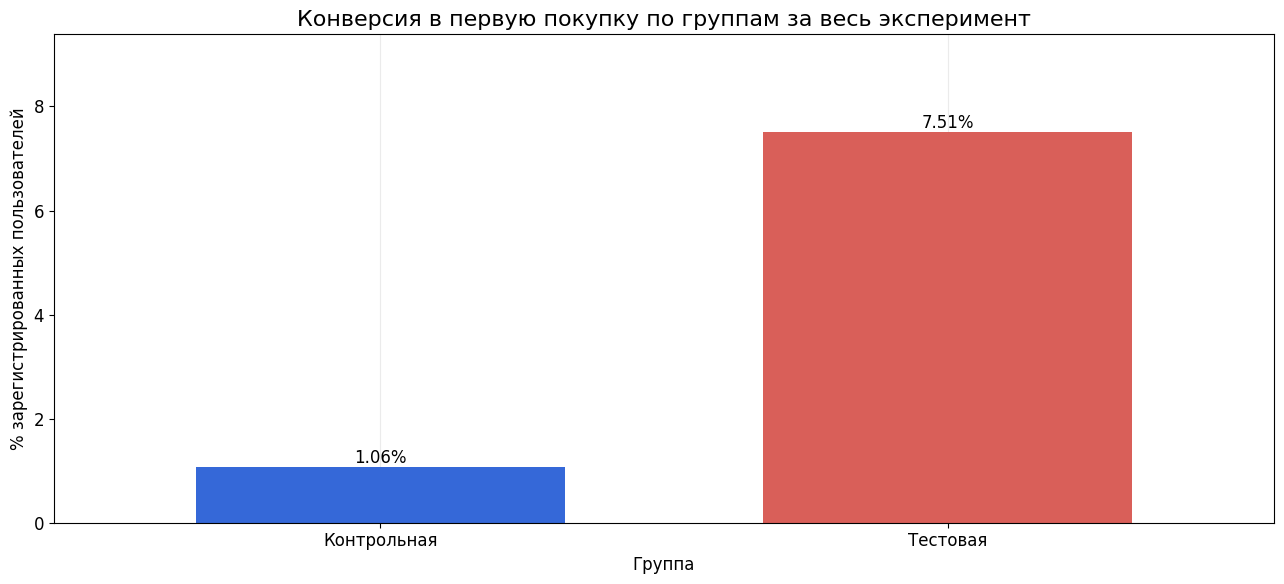

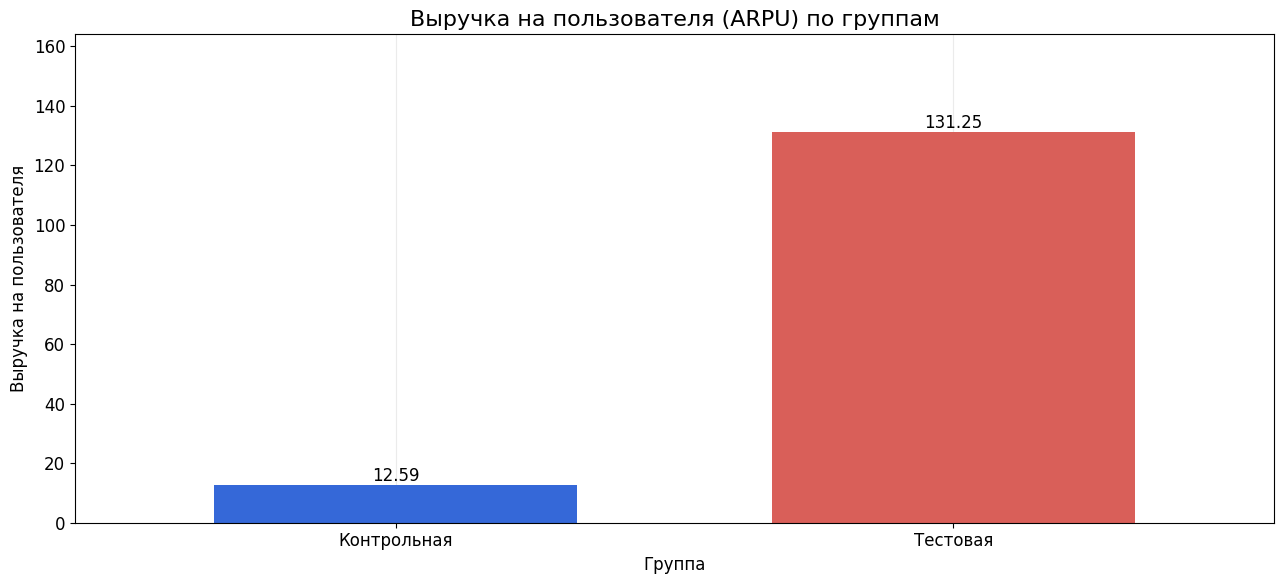

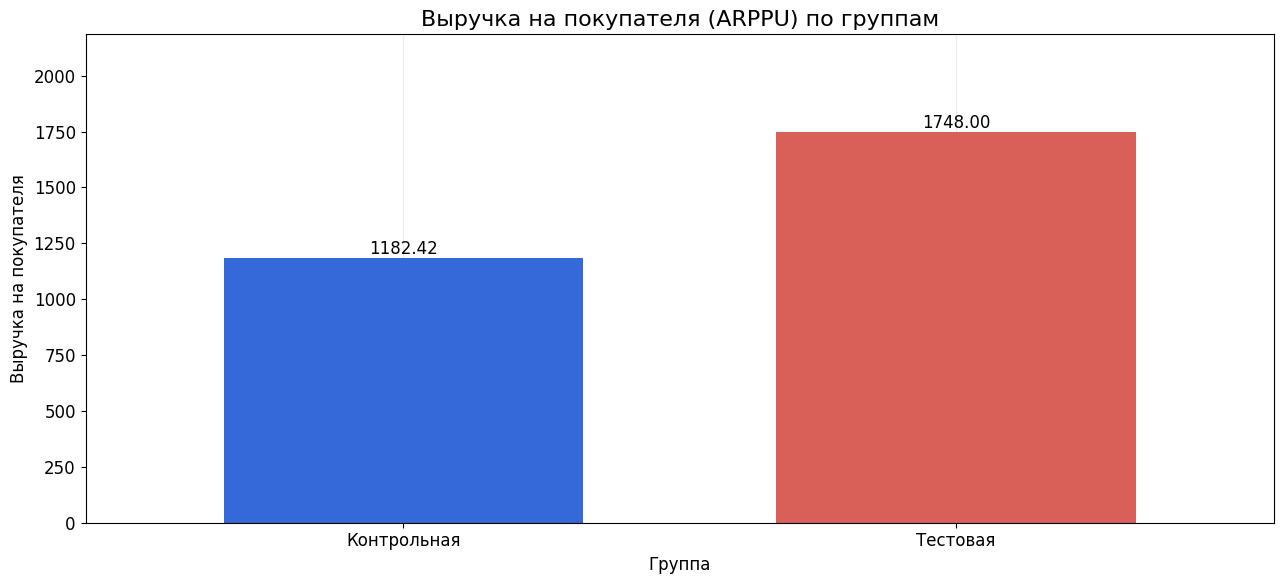

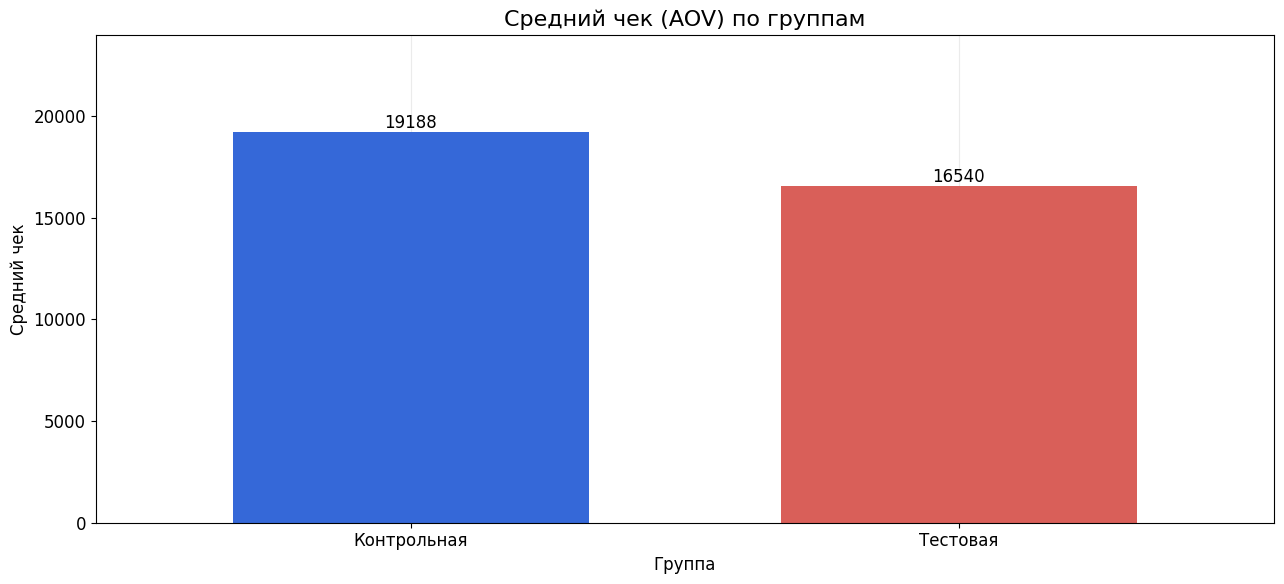

In [46]:
conversion_plot = group_metrics['conversion_percent'].reindex(
    ['control', 'treatment']
)
conversion_plot.index = ['Контрольная', 'Тестовая']
ax = conversion_plot.plot(
    kind='bar',
    figsize=(13, 6),
    color=['#3568d8', '#d95f59'],
    width=0.65
)
ax.set_title(
    'Конверсия в первую покупку по группам за весь эксперимент'
)
ax.set_xlabel('Группа')
ax.set_ylabel('% зарегистрированных пользователей')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, conversion_plot.max() * 1.25)
ax.grid(axis='y', alpha=0.2)
for bar in ax.patches:
    value = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f'{value:.2f}%',
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

auxiliary_plot_specs = [
    (
        'ARPU',
        'arpu',
        'Выручка на пользователя (ARPU) по группам',
        'Выручка на пользователя',
        '%.2f'
    ),
    (
        'ARPPU',
        'arppu',
        'Выручка на покупателя (ARPPU) по группам',
        'Выручка на покупателя',
        '%.2f'
    ),
    (
        'AOV',
        'aov',
        'Средний чек (AOV) по группам',
        'Средний чек',
        '%.0f'
    )
]

for metric_name, column_name, title, y_label, value_format in (
    auxiliary_plot_specs
):
    plot_values = group_metrics[column_name].reindex(
        ['control', 'treatment']
    )
    plot_values.index = ['Контрольная', 'Тестовая']
    ax = plot_values.plot(
        kind='bar',
        figsize=(13, 6),
        color=['#3568d8', '#d95f59'],
        width=0.65
    )
    ax.set_title(title)
    ax.set_xlabel('Группа')
    ax.set_ylabel(y_label)
    ax.tick_params(axis='x', rotation=0)
    ax.set_ylim(0, plot_values.max() * 1.25)
    ax.grid(axis='y', alpha=0.2)
    for bar in ax.patches:
        value = bar.get_height()
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            value_format % value,
            ha='center',
            va='bottom'
        )
    plt.tight_layout()
    plt.show()

#### Промежуточный вывод по основной и вспомогательным метрикам

Конверсия в первую покупку выросла с 1,06% в контрольной группе до 7,51% в тестовой. Абсолютный эффект составил +6,44 п.п., 95%-й доверительный интервал — от +5,04 до +7,96 п.п.; p-value = 3,16e-18.

Выручка на пользователя выросла с 12,59 до 131,25 и остаётся статистически значимой после поправки Холма. Выручка на покупателя выросла с 1 182,42 до 1 748,00, но скорректированный p-value равен 0,099. Средний чек снизился с 19 188,07 до 16 539,64, однако различие также незначимо: p-value = 0,542.

Подтверждённый рост выручки на пользователя связан прежде всего с увеличением доли покупателей. Доказательств изменения выручки на покупателя или среднего чека недостаточно.

Барьерная метрика: общая валовая выручка


,Показатель,Значение
0,Выручка контрольной группы,18 918.65
1,Выручка тестовой группы,192 279.85
2,Абсолютное изменение,173 361.21
3,"Относительное изменение, %",916.35


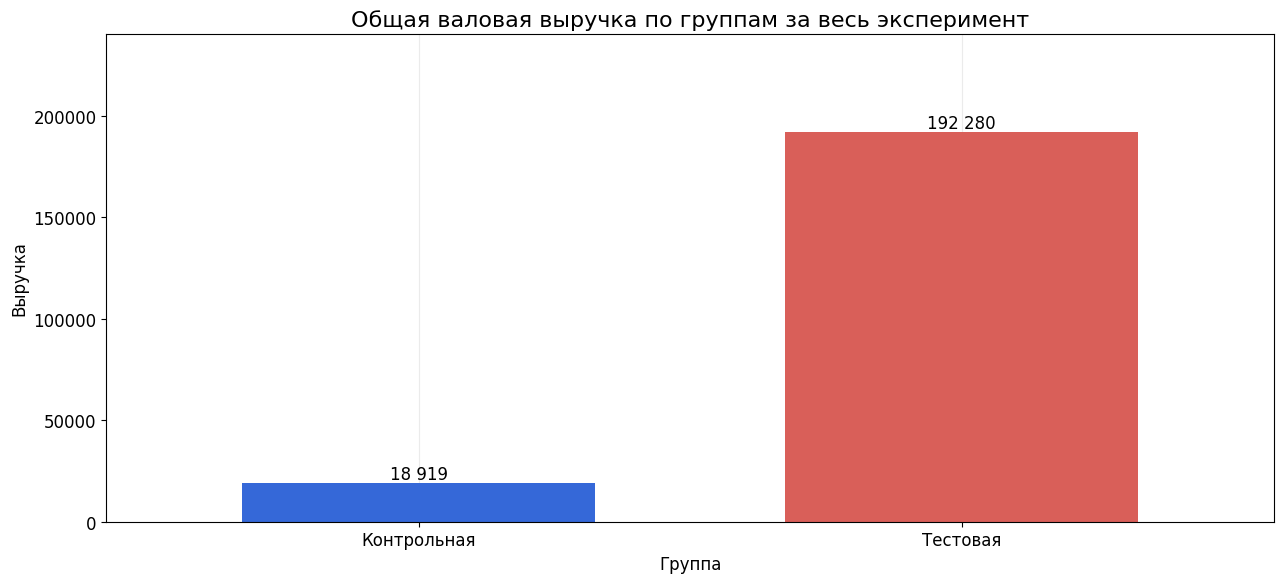

Стоимость бонусов отсутствует, поэтому рассчитана валовая, а не чистая выручка.


In [47]:
revenue_by_group = analysis_data.groupby('group')['revenue'].sum()
control_revenue = revenue_by_group['control']
treatment_revenue = revenue_by_group['treatment']

revenue_difference = treatment_revenue - control_revenue
revenue_change_percent = (
    revenue_difference / control_revenue * 100
)

revenue_summary = pd.DataFrame({
    'Показатель': [
        'Выручка контрольной группы',
        'Выручка тестовой группы',
        'Абсолютное изменение',
        'Относительное изменение, %'
    ],
    'Значение': [
        control_revenue,
        treatment_revenue,
        revenue_difference,
        revenue_change_percent
    ]
})

revenue_summary['Значение'] = revenue_summary['Значение'].map(
    lambda value: f'{value + 1e-9:,.2f}'.replace(',', ' ')
)

print('Барьерная метрика: общая валовая выручка')
display(revenue_summary)

revenue_plot = revenue_by_group.reindex(
    ['control', 'treatment']
)
revenue_plot.index = ['Контрольная', 'Тестовая']

ax = revenue_plot.plot(
    kind='bar',
    figsize=(13, 6),
    color=['#3568d8', '#d95f59'],
    width=0.65
)
ax.set_title(
    'Общая валовая выручка по группам за весь эксперимент'
)
ax.set_xlabel('Группа')
ax.set_ylabel('Выручка')
ax.tick_params(axis='x', rotation=0)
ax.set_ylim(0, revenue_plot.max() * 1.25)
ax.grid(axis='y', alpha=0.2)

revenue_labels = [
    f'{value:,.0f}'.replace(',', ' ')
    for value in revenue_plot
]
for bar, label in zip(ax.patches, revenue_labels):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        label,
        ha='center',
        va='bottom'
    )
plt.tight_layout()
plt.show()

print(
    'Стоимость бонусов отсутствует, поэтому рассчитана '
    'валовая, а не чистая выручка.'
)

In [48]:
arpu_result = auxiliary_results[
    auxiliary_results['metric'] == 'ARPU'
].iloc[0]

decision_summary = pd.DataFrame({
    'Критерий': [
        'Баланс итогового сплита',
        'Эффект выше MDE',
        'Конверсия выше в тестовой группе',
        'Доверительный интервал конверсии выше нуля',
        'Выручка на пользователя не снизилась',
        'Барьерная валовая выручка не снизилась',
        'Можно оценить чистую выручку'
    ],
    'Статус': [
        srm_pvalue >= 0.05,
        primary_difference * 100 > mde_pp,
        primary_difference > 0,
        primary_ci_low > 0,
        arpu_result['ci_low'] >= 0,
        treatment_revenue >= control_revenue,
        False
    ],
    'Комментарий': [
        f'p-value={srm_pvalue:.3f}',
        f'эффект={primary_difference * 100:.2f} п.п.; MDE={mde_pp:.2f} п.п.',
        f'p-value={primary_pvalue:.3g}',
        f'95% ДИ [{primary_ci_low * 100:.2f}; {primary_ci_high * 100:.2f}] п.п.',
        f'95% ДИ разницы [{arpu_result["ci_low"]:.2f}; {arpu_result["ci_high"]:.2f}]',
        f'контрольная={control_revenue:.2f}; тестовая={treatment_revenue:.2f}',
        'нет данных о стоимости бонусов'
    ]
})
decision_summary['Статус'] = decision_summary['Статус'].map({
    True: 'Да',
    False: 'Нет'
})

print('Итоговая проверка критериев эксперимента')
display(decision_summary)

Итоговая проверка критериев эксперимента


,Критерий,Статус,Комментарий
0,Баланс итогового сплита,Да,p-value=0.485
1,Эффект выше MDE,Да,эффект=6.44 п.п.; MDE=1.77 п.п.
2,Конверсия выше в тестовой группе,Да,p-value=3.16e-18
3,Доверительный интервал конверсии выше нуля,Да,95% ДИ [5.04; 7.96] п.п.
4,Выручка на пользователя не снизилась,Да,95% ДИ разницы [81.78; 159.14]
5,Барьерная валовая выручка не снизилась,Да,контрольная=18918.64; тестовая=192279.85
6,Можно оценить чистую выручку,Нет,нет данных о стоимости бонусов


#### Промежуточный вывод по барьерной метрике

Общая валовая выручка составила 18 918,65 в контрольной группе и 192 279,85 в тестовой. Абсолютный прирост равен 173 361,21, относительный — 916,3%. Барьерная метрика не снизилась.

Сравнение является описательным: общая выручка — агрегат на уровне группы, поэтому отдельный статистический тест для неё не проводится. Без стоимости бонусов нельзя оценить чистый финансовый результат.

## Выводы по этапу 5

Эксперимент проанализирован после полного завершения в ITT-логике: в расчёт вошли все 2 968 распределённых пользователей — 1 503 в контрольной и 1 465 в тестовой группе. 

### Качество эксперимента

Нарушений баланса не обнаружено: SRM-тест дал p-value = 0,486; распределения групп по датам регистрации, полу и возрасту статистически не различаются. Пересечений между группами и пропущенных профилей нет.

Набор участников продолжался 26 дней вместо заявленных трёх недель. Также обнаружено восемь событий до регистрации; они не влияют на расчёт покупок, но указывают на отдельную проблему качества событийных данных.

При исторической 21-дневной конверсии TikTok 2,24% и фактических размерах групп MDE составил 1,77 п.п. при мощности 80%.

### Результаты эксперимента

Конверсия в первую покупку составила 1,06% в контрольной и 7,51% в тестовой группе. Абсолютный эффект равен +6,44 п.п., 95%-й доверительный интервал — от +5,04 до +7,96 п.п., p-value = 3,16e-18. Эффект статистически значим и выше MDE.

Выручка на пользователя выросла с 12,59 до 131,25; результат значим после поправки Холма. Для выручки на покупателя и среднего чека статистически значимых различий после поправки не обнаружено.

Общая валовая выручка выросла с 18 918,65 до 192 279,85: на 173 361,21, или 916,3%. Барьерная метрика не снизилась.

### Ограничения

Чистый финансовый эффект определить нельзя, поскольку стоимость бонусов отсутствует. Решение о полном запуске следует принимать после сопоставления прироста выручки со стоимостью бонусной программы.

Пользователи имеют разную длительность наблюдения: зарегистрированные ближе к завершению эксперимента наблюдались меньше. Результат относится к конверсии до общего момента завершения эксперимента, а не к одинаковому числу дней жизни каждого пользователя.

### Рекомендации

В общем и целом эскпиримент можно считать удачным - мы пронаблюдали статистически значимый рост целевой метрики - конверсии в первую покупку, так же статистически значимо увеличилась выручка на пользователя (ARPU), а значит больше пользователей, привлеченных из TikTok, стали делать покупки, что и явлвлось изначальной целью эксперимента. Средний чек пользователей тестовой групппы оказался ниже, но результат статистически не значим, как и рост ARPPU, что можно было ожидать, ведь эксперимент стимулирует пользователей делать покупки, но не напрален на увелечение количества или цены товаров. Выручка же тестовой группы не только не упала, но и показала рост, хотя этот рост мы не можем статистически подтвердить. бонус можно раскатывать на всю аудиторию, привлекаемую из TikTok.